# EDA: ไข้เลือดออก × สภาพอากาศ (TRENDS 2016-2025)

**โปรเจกต์:** CSS 342 — Data Science and Data Engineering, KMUTT 2569  
**คำถามวิจัย:** สภาพอากาศ (ฝน, tmax, tmin) ช่วยพยากรณ์การเติบโตของไข้เลือดออกรายจังหวัดล่วงหน้า 4 สัปดาห์ได้หรือไม่?

**โครงสร้าง notebook:**
- **ส่วนที่ 5: การเตรียมข้อมูล** — data cleaning, transformation, integration, feature engineering, temporal/spatial handling
- **ส่วนที่ 6: EDA** — ลักษณะทั่วไป, สถิติเชิงพรรณนา, การกระจาย, correlation, แนวโน้มเวลา, รูปแบบเชิงพื้นที่

**ข้อมูล:** TRENDS 2016-2025 (ไข้เลือดออกรายสัปดาห์ 77 จังหวัด) + อากาศรายวัน ERA5 ผ่าน Open-Meteo  
**หน่วยวิเคราะห์:** จังหวัด-สัปดาห์ = 40,579 แถว (77 จังหวัด × ~527 สัปดาห์)

In [1]:
import sys, warnings, math
from pathlib import Path
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import spearmanr
try:
    from statsmodels.tsa.stattools import adfuller
    from statsmodels.tsa.seasonal import seasonal_decompose
    from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
    HAS_STATSMODELS = True
except ImportError:
    HAS_STATSMODELS = False
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="muted", font_scale=1.15)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
import tomllib

# ---- ROOT และ path หลัก ----
ROOT = Path("__file__").resolve().parent.parent  # notebooks/ -> root
# ถ้า __file__ ไม่ใช่ไฟล์จริง (เช่นใน Jupyter) ให้ fallback ตาม cwd
if not (ROOT / "config").exists():
    ROOT = Path.cwd().parent
    if not (ROOT / "config").exists():
        ROOT = Path.cwd()

DB_PATH = ROOT / "data" / "pipeline.duckdb"
print(f"ROOT     : {ROOT}")
print(f"DB_PATH  : {DB_PATH}  (exists={DB_PATH.exists()})")

# ---- อ่าน config ----
with open(ROOT / "config" / "analysis.toml", "rb") as f:
    CFG = tomllib.load(f)
with open(ROOT / "config" / "pipeline.toml", "rb") as f:
    PCFG = tomllib.load(f)

TARGET      = CFG["target"]["name"]          # "D"
SEED        = CFG["folds"]["seed"]            # 342
H           = CFG["target"]["horizon_weeks"]  # 4
MAX_WX_LAG  = max(CFG["features"]["M1"]["wx_lags"])  # 4
FOURIER_K   = CFG["features"]["M0"]["seas_fourier_k"]  # 3
WX_BASE     = {"rain": "rain_wk_mm", "tmax": "tmax_mean_c", "tmin": "tmin_mean_c"}

MAIN_FOLDS = [
    {"name": f"F{i+1}", "test_year": y,
     "train_years": (2016, y - 1)}
    for i, y in enumerate(CFG["folds"]["test_years_main"])
]
SUPP_FOLDS = [
    {"name": f"S{i+1}", "test_year": y,
     "train_years": (2016, y - 1)}
    for i, y in enumerate(CFG["folds"]["test_years_supplementary"])
]

print(f"\nTARGET={TARGET}  SEED={SEED}  H={H}  MAX_WX_LAG={MAX_WX_LAG}  FOURIER_K={FOURIER_K}")
print(f"MAIN_FOLDS : {[f['name'] for f in MAIN_FOLDS]}")
print(f"SUPP_FOLDS : {[f['name'] for f in SUPP_FOLDS]}")

# ---- DuckDB connection (read-only) ----
con = duckdb.connect(str(DB_PATH), read_only=True)
print("\n=== SHOW ALL TABLES ===")
con.execute("SHOW ALL TABLES").df()

ROOT     : /Users/chanut/Documents/DataScience/dengue_pipeline
DB_PATH  : /Users/chanut/Documents/DataScience/dengue_pipeline/data/pipeline.duckdb  (exists=True)

TARGET=D  SEED=342  H=4  MAX_WX_LAG=4  FOURIER_K=3
MAIN_FOLDS : ['F1', 'F2', 'F3', 'F4', 'F5']
SUPP_FOLDS : ['S1', 'S2']

=== SHOW ALL TABLES ===


,database,schema,name,column_names,column_types,temporary
0,pipeline,core,weather_daily,"[data_version, _ord, P-code, Province, date, p...","[VARCHAR, BIGINT, VARCHAR, VARCHAR, TIMESTAMP,...",False
1,pipeline,core,weather_daily_latest,"[data_version, P-code, Province, date, precip_...","[VARCHAR, VARCHAR, VARCHAR, TIMESTAMP, DOUBLE,...",False
2,pipeline,mart,h_decisions,"[created_at, decisions_json]","[VARCHAR, VARCHAR]",False
3,pipeline,mart,h_placebo,"[fold, var, lag, rho_real, placebo_median, pla...","[VARCHAR, VARCHAR, INTEGER, DOUBLE, DOUBLE, DO...",False
4,pipeline,mart,h_results,"[fold, var, lag, analysis, median_rho, median_...","[VARCHAR, VARCHAR, INTEGER, VARCHAR, DOUBLE, D...",False
5,pipeline,mart,results,"[run_id, config_hash, data_version, fold, mode...","[VARCHAR, VARCHAR, VARCHAR, VARCHAR, VARCHAR, ...",False
6,pipeline,mart,trends_weather,"[data_version, _ord, Country, Year, Month, Epi...","[VARCHAR, BIGINT, VARCHAR, BIGINT, BIGINT, BIG...",False
7,pipeline,mart,trends_weather_latest,"[data_version, Country, Year, Month, Epi week,...","[VARCHAR, VARCHAR, BIGINT, BIGINT, BIGINT, TIM...",False
8,pipeline,ops,audit_log,"[run_id, stage, rule_id, severity, outcome, me...","[VARCHAR, VARCHAR, VARCHAR, VARCHAR, VARCHAR, ...",False
9,pipeline,ops,data_version,"[data_version, written_at, pipeline_version, m...","[VARCHAR, VARCHAR, VARCHAR, VARCHAR]",False


In [3]:
import math
import duckdb
import pandas as pd


def build_features_sql(source, con=None):
    '''build_features เวอร์ชัน DuckDB: คืน DataFrame คอลัมน์/ลำดับ/ค่าเท่ากับ build_features(raw)
    source = ชื่อ table/view ใน DuckDB (เช่น "mart.trends_weather_latest") หรือ DataFrame (raw)
    con    = duckdb connection (ไม่ใส่ = ใช้ in-memory ชั่วคราว)
    ใช้ค่าคงที่จากเซลล์ตั้งค่า: WX_BASE, MAX_WX_LAG, FOURIER_K, TARGET
    '''
    own = con is None
    if own:
        con = duckdb.connect()
    try:
        if isinstance(source, pd.DataFrame):
            con.register("_bf_src_df", source)
            src = "_bf_src_df"
        else:
            src = source
        cols = con.execute(f"SELECT * FROM {src} LIMIT 0").df().columns
        drop = [c for c in ("data_version", "_ord") if c in cols]
        base = f"SELECT * EXCLUDE ({', '.join(drop)}) FROM {src}" if drop else f"SELECT * FROM {src}"

        # ---- ตรวจเหมือน _national_block: ทุกสัปดาห์ต้องมีจังหวัดครบ ----
        n_prov, bad = con.execute(f'''
            WITH s AS ({base}), t AS (SELECT count(DISTINCT "P-code") AS n FROM s)
            SELECT (SELECT n FROM t),
                   (SELECT count(*) FROM (SELECT "Week start" FROM s GROUP BY 1
                                          HAVING count(DISTINCT "P-code") <> (SELECT n FROM t)))''').fetchone()
        assert bad == 0, "บางสัปดาห์มีจังหวัดไม่ครบ"
        regions = [r[0] for r in con.execute(
            f'SELECT DISTINCT CAST("Health region" AS INTEGER) FROM ({base}) ORDER BY 1').fetchall()]

        W = 'OVER (PARTITION BY "P-code" ORDER BY "Week start")'
        W4 = ('OVER (PARTITION BY "P-code" ORDER BY "Week start" '
              'ROWS BETWEEN 3 PRECEDING AND CURRENT ROW)')
        dd = lambda a, b: f"date_diff('day', CAST({a} AS DATE), CAST({b} AS DATE))"
        wx = list(WX_BASE.items())

        # s1: ค่า c / w รายสัปดาห์เต็ม, ผลรวมหน้าต่าง 4 สัปดาห์, วันที่ของแถวข้างเคียง
        s1 = ['*',
              'CAST("Population" AS DOUBLE) AS pop',
              'CASE WHEN week_days = 7 THEN CAST("Dengue total" AS DOUBLE) END AS c']
        s1 += [f'CASE WHEN week_days = 7 THEN CAST("{col}" AS DOUBLE) END AS w_{key}' for key, col in wx]
        _ws_needed = sorted(set(range(1, MAX_WX_LAG + 1)) | {3, 7})
        s1 += [f'lag("Week start", {k}) {W} AS ws_l{k}' for k in _ws_needed]
        s1 += [f'lead("Week start", 4) {W} AS ws_f4']
        s1 += [f'CASE WHEN count(CASE WHEN week_days = 7 THEN "Dengue total" END) {W4} = 4 '
               f'THEN sum(CASE WHEN week_days = 7 THEN CAST("Dengue total" AS DOUBLE) END) {W4} END AS s4']

        # s2: lag/lead ของ c, w, s4 พร้อมเงื่อนไขความต่อเนื่องของวันที่
        s2 = ['*']
        s2 += [f'CASE WHEN {dd(f"ws_l{k}", chr(34)+"Week start"+chr(34))} = {7*k} THEN lag(c, {k}) {W} END AS c_l{k}'
               for k in (1, 2, 3)]
        for key, _ in wx:
            s2 += [f'CASE WHEN {dd(f"ws_l{k}", chr(34)+"Week start"+chr(34))} = {7*k} '
                   f'THEN lag(w_{key}, {k}) {W} END AS w_{key}_l{k}' for k in range(1, MAX_WX_LAG + 1)]
        s2 += [f'CASE WHEN {dd("ws_l3", chr(34)+"Week start"+chr(34))} = 21 THEN s4 END AS s4_b3',
               f'CASE WHEN {dd("ws_l7", chr(34)+"Week start"+chr(34))} = 49 THEN lag(s4, 4) {W} END AS s4_b7',
               f'CASE WHEN {dd(chr(34)+"Week start"+chr(34), "ws_f4")} = 28 THEN lead(s4, 4) {W} END AS s4_f4',
               f'lead("Week end", 4) {W} AS label_end_']

        # s3: อัตรา R และ target
        s3 = ['*', 's4_b3 / pop * 1e5 AS R_prev', 's4_b7 / pop * 1e5 AS R_prev2',
              's4_f4 / pop * 1e5 AS R_next']

        out = ['p.*', f'ln(1 + R_next) - ln(1 + R_prev) AS "{TARGET}"',
               'label_end_ AS label_end', 'R_prev AS diag_R_prev', 'R_next AS diag_R_next',
               's4_b3 + s4_f4 AS diag_cases_8w',
               'ln(1 + c / pop * 1e5) AS hist_lograte_lag0']
        out += [f'ln(1 + c_l{k} / pop * 1e5) AS hist_lograte_lag{k}' for k in (1, 2, 3)]
        out += ['ln(1 + R_prev) AS hist_logR_prev', 'ln(1 + R_prev2) AS hist_logR_prev2',
                'ln(1 + R_prev) - ln(1 + R_prev2) AS hist_growth_prev']
        for key, _ in wx:
            out += [f'w_{key} AS wk_{key}', f'w_{key} AS wx_{key}_lag0']
            out += [f'w_{key}_l{k} AS wx_{key}_lag{k}' for k in range(1, MAX_WX_LAG + 1)]
        out += ['n.nat_lograte_lag0', 'n.nat_logR_prev', 'n.nat_growth_prev']
        ang = 'pi() * 2 * dayofyear(p."Week start") / 365.25'
        for k in range(1, FOURIER_K + 1):
            out += [f'sin({k} * {ang}) AS seas_sin{k}', f'cos({k} * {ang}) AS seas_cos{k}']
        out += [f'CAST(CAST(p."Health region" AS INTEGER) = {r} AS BIGINT) AS reg_{r}' for r in regions]

        # แยก p.* ออกจากคอลัมน์ช่วย (pop, c, w_*, ws_*, s4*, ...) ให้เหลือเฉพาะคอลัมน์เดิมของ raw
        helper = (['pop', 'c', 's4', 'ws_f4', 'label_end_', 's4_b3', 's4_b7', 's4_f4', 'R_prev', 'R_prev2', 'R_next']
                  + [f'ws_l{k}' for k in _ws_needed] + [f'c_l{k}' for k in (1, 2, 3)]
                  + [f'w_{key}' for key, _ in wx]
                  + [f'w_{key}_l{k}' for key, _ in wx for k in range(1, MAX_WX_LAG + 1)])
        out[0] = f'p.* EXCLUDE ({"、".join(helper)})'
        out[0] = f'p.* EXCLUDE ({", ".join(helper)})'

        sql = f'''
        WITH src AS ({base}),
        s1 AS (SELECT {", ".join(s1)} FROM src),
        s2 AS (SELECT {", ".join(s2)} FROM s1),
        p  AS (SELECT {", ".join(s3)} FROM s2),
        n1 AS (SELECT "Week start" AS ws, sum(CAST("Dengue total" AS DOUBLE)) AS cases,
                      sum(CAST("Population" AS DOUBLE)) AS pop, min(week_days) AS wd
               FROM src GROUP BY 1),
        n2 AS (SELECT ws, pop, CASE WHEN wd = 7 THEN cases END AS c,
                      lag(ws, 3) OVER o AS ws_l3, lag(ws, 7) OVER o AS ws_l7 FROM n1
               WINDOW o AS (ORDER BY ws)),
        n3 AS (SELECT *, CASE WHEN count(c) OVER (ORDER BY ws ROWS BETWEEN 3 PRECEDING AND CURRENT ROW) = 4
                              THEN sum(c) OVER (ORDER BY ws ROWS BETWEEN 3 PRECEDING AND CURRENT ROW) END AS s4
               FROM n2),
        n4 AS (SELECT ws,
                      CASE WHEN {dd("ws_l3", "ws")} = 21 THEN s4 END / pop * 1e5 AS R_prev,
                      CASE WHEN {dd("ws_l7", "ws")} = 49 THEN lag(s4, 4) OVER (ORDER BY ws) END / pop * 1e5 AS R_prev2,
                      c, pop FROM n3),
        n AS (SELECT ws AS "Week start", ln(1 + c / pop * 1e5) AS nat_lograte_lag0,
                     ln(1 + R_prev) AS nat_logR_prev, ln(1 + R_prev) - ln(1 + R_prev2) AS nat_growth_prev FROM n4)
        SELECT {", ".join(out)}
        FROM p LEFT JOIN n ON p."Week start" = n."Week start"
        ORDER BY p."P-code", p."Week start"
        '''
        return con.execute(sql).df()
    finally:
        if own:
            con.close()

In [4]:
# ---- Build features ----
print("Building features from mart.trends_weather_latest ...")
df = build_features_sql("mart.trends_weather_latest", con)
print(f"df.shape = {df.shape}")
print(f"คอลัมน์ทั้งหมด: {df.shape[1]}")

# ตรวจค่าอ้างอิง
n_D_hist = df[df["D"].notna() & df["hist_growth_prev"].notna()].shape[0]
print(f"\nแถวที่มี D และ hist_growth_prev: {n_D_hist}")
assert n_D_hist == 32802, f"คาดหวัง 32,802 ได้ {n_D_hist}"
print("✓ ตรง 32,802 แถว")

print(f"\nตัวอย่างคอลัมน์:")
print(df.columns.tolist()[:20], "...")
df.head(3)

Building features from mart.trends_weather_latest ...
df.shape = (40579, 96)
คอลัมน์ทั้งหมด: 96

แถวที่มี D และ hist_growth_prev: 32802
✓ ตรง 32,802 แถว

ตัวอย่างคอลัมน์:
['Country', 'Year', 'Month', 'Epi week', 'Week start', 'Week end', 'Health region', 'P-code', 'Province', 'Dengue fever (DF)', 'Dengue haemorrhagic fever (DHF)', 'Dengue shock syndrome (DSS)', 'Dengue total', 'Chikungunya', 'HFMD', 'Dengue rate per 100,000', 'Chikungunya rate per 100,000', 'HFMD rate per 100,000', 'Centroid latitude', 'Centroid longitude'] ...


,Country,Year,Month,Epi week,Week start,Week end,Health region,P-code,Province,Dengue fever (DF),...,reg_4,reg_5,reg_6,reg_7,reg_8,reg_9,reg_10,reg_11,reg_12,reg_13
0,Thailand,2016,1,1,2016-01-03,2016-01-09,13,TH10,Bangkok,336,...,0,0,0,0,0,0,0,0,0,1
1,Thailand,2016,1,2,2016-01-10,2016-01-16,13,TH10,Bangkok,253,...,0,0,0,0,0,0,0,0,0,1
2,Thailand,2016,1,3,2016-01-17,2016-01-23,13,TH10,Bangkok,193,...,0,0,0,0,0,0,0,0,0,1


In [5]:
# ---- Feature groups ----
HIST_FEATS = [
    "hist_lograte_lag0", "hist_lograte_lag1", "hist_lograte_lag2", "hist_lograte_lag3",
    "hist_logR_prev", "hist_logR_prev2", "hist_growth_prev",
]
NAT_FEATS  = ["nat_lograte_lag0", "nat_logR_prev", "nat_growth_prev"]
SEAS_FEATS = ([f"seas_sin{k}" for k in range(1, FOURIER_K+1)] +
              [f"seas_cos{k}" for k in range(1, FOURIER_K+1)])
REG_FEATS  = [c for c in df.columns if c.startswith("reg_")]
WX_FEATS   = [f"wx_{v}_lag{k}" for v in ["rain", "tmax", "tmin"] for k in range(MAX_WX_LAG+1)]
WXA_FEATS  = [f"wxa_{v}_lag{k}" for v in ["rain", "tmax", "tmin"] for k in range(MAX_WX_LAG+1)]

FEATURE_GROUPS = {
    "hist": HIST_FEATS,
    "nat":  NAT_FEATS,
    "seas": SEAS_FEATS,
    "reg":  REG_FEATS,
    "wx":   WX_FEATS,
    "wxa":  WXA_FEATS,
}

M0_FEATURES = HIST_FEATS + NAT_FEATS + SEAS_FEATS + REG_FEATS
M1_FEATURES = M0_FEATURES + WX_FEATS + WXA_FEATS
ALL_FEATURES = M1_FEATURES

print(f"Feature groups:")
for g, cols in FEATURE_GROUPS.items():
    print(f"  {g:6s}: {len(cols)} features")
print(f"\nM0: {len(M0_FEATURES)} features")
print(f"M1: {len(M1_FEATURES)} features (+{len(M1_FEATURES)-len(M0_FEATURES)} wx+wxa)")

Feature groups:
  hist  : 7 features
  nat   : 3 features
  seas  : 6 features
  reg   : 13 features
  wx    : 15 features
  wxa   : 15 features

M0: 29 features
M1: 59 features (+30 wx+wxa)


In [6]:
import duckdb

# ลงทะเบียน df (ตารางฟีเจอร์ฐาน) ให้ DuckDB อ่านโดยตรง (ไม่คัดลอกข้อมูล)
_fcon = duckdb.connect()
_fcon.register("feat", df)

_FOLD_CACHE = {}


def _fold_sql(fold):
    '''SQL เดียว: climatology (เฉพาะก่อน test_start) → anomaly → lag ของ anomaly → ตัดแบ่ง train/test'''
    W = 'OVER (PARTITION BY "P-code" ORDER BY "Week start")'
    keys = list(WX_BASE)
    clim = ", ".join(f'avg(wk_{k}) AS wk_{k}_clim' for k in keys)
    anom = ", ".join(f'wk_{k} - wk_{k}_clim AS anom_{k}' for k in keys)
    wxa = ", ".join(
        f'anom_{k} AS wxa_{k}_lag0' if i == 0 else
        f"CASE WHEN date_diff('day', CAST(lag(\"Week start\", {i}) {W} AS DATE), CAST(\"Week start\" AS DATE)) = {7*i} "
        f'THEN lag(anom_{k}, {i}) {W} END AS wxa_{k}_lag{i}'
        for k in keys for i in range(MAX_WX_LAG + 1))
    usable = " AND ".join([f'"{TARGET}" IS NOT NULL'] + [f'"{c}" IS NOT NULL' for c in ALL_FEATURES])
    lo, hi = fold["train_years"]
    return f'''
    WITH clim AS (
        SELECT "P-code", "Month", {clim} FROM feat
        WHERE week_days = 7 AND "Week end" < $1 GROUP BY 1, 2),
    a AS (
        SELECT f.*, {", ".join(f"c.wk_{k}_clim" for k in keys)}
        FROM feat f LEFT JOIN clim c ON f."P-code" = c."P-code" AND f."Month" = c."Month"),
    b AS (SELECT *, {anom} FROM a),
    d AS (SELECT *, {wxa} FROM b)
    SELECT * EXCLUDE (_tr, _te) , _tr, _te FROM (
        SELECT *, ({usable}) AS _ok,
               ("Year" BETWEEN {lo} AND {hi} AND label_end < $1) AS _tr,
               ("Year" = {fold["test_year"]}) AS _te
        FROM d) WHERE _ok AND (_tr OR _te)
    ORDER BY "P-code", "Week start"
    '''


def get_fold_sql(fold):
    '''เหมือน get_fold เดิม: dict(train, test, test_start) แต่ทำ anomaly + ตัดแบ่งด้วย SQL; ผลถูก cache'''
    if fold["name"] in _FOLD_CACHE:
        return _FOLD_CACHE[fold["name"]]
    test_start = pd.Timestamp(f"{fold['test_year']}-01-01")
    d = _fcon.execute(_fold_sql(fold), [test_start.to_pydatetime()]).df()
    tr = d[d["_tr"]].drop(columns=["_ok", "_tr", "_te"]).reset_index(drop=True)
    te = d[d["_te"]].drop(columns=["_ok", "_tr", "_te"]).reset_index(drop=True)

    # --- unit test ของ fold (หยุดทันทีถ้าไม่ผ่าน) ---
    assert tr["label_end"].max() < test_start, "label ของ train ล้ำเข้าช่วงทดสอบ"
    assert te["Week start"].min() >= test_start, "test เริ่มก่อนต้นปีทดสอบ"
    assert set(tr["P-code"]) <= set(te["P-code"]) | set(tr["P-code"]), "ตรวจจังหวัด"
    out = {"train": tr, "test": te, "test_start": test_start}
    _FOLD_CACHE[fold["name"]] = out
    return out


get_fold = get_fold_sql      # ให้ section อื่นที่เรียก get_fold ใช้ของ SQL ต่อได้เลย

summary = []
for f in MAIN_FOLDS + SUPP_FOLDS:
    fd = get_fold(f)
    summary.append({"fold": f["name"], "train_years": f"{f['train_years'][0]}-{f['train_years'][1]}",
                    "test_year": f["test_year"], "n_train": len(fd["train"]), "n_test": len(fd["test"]),
                    "last_train_label_end": fd["train"]["label_end"].max().date()})
pd.DataFrame(summary)

,fold,train_years,test_year,n_train,n_test,last_train_label_end
0,F1,2016-2018,2019,10241,3080,2018-12-29
1,F2,2016-2021,2022,19481,3465,2021-12-25
2,F3,2016-2022,2023,22638,3696,2022-12-31
3,F4,2016-2023,2024,26642,3080,2023-12-30
4,F5,2016-2024,2025,29722,3080,2024-12-28
5,S1,2016-2019,2020,13321,3080,2019-12-28
6,S2,2016-2020,2021,16401,3080,2020-12-26


## ส่วนที่ 5: การเตรียมข้อมูล

In [7]:
import re
# ---- 5.1 Data Cleaning: ตรวจ null ต่อคอลัมน์ ----
print("=== 5.1 Data Cleaning ===")

# สร้าง SQL ตรวจ null ทุกคอลัมน์ใน mart.trends_weather_latest
cols_raw = con.execute("SELECT * FROM mart.trends_weather_latest LIMIT 0").df().columns.tolist()
def _q(c):
    """quote ชื่อคอลัมน์ถ้าไม่ใช่ alphanumeric+underscore"""
    return f'"{c}"' if not re.match(r'^\w+$', c) else c
null_exprs = ", ".join(
    f"SUM(CASE WHEN {_q(c)} IS NULL THEN 1 ELSE 0 END) AS \"null_{c}\""
    for c in cols_raw
)
null_df_wide = con.execute(f"SELECT COUNT(*) AS total, {null_exprs} FROM mart.trends_weather_latest").df()
total_rows = null_df_wide["total"].iloc[0]

null_long = []
for c in cols_raw:
    key = f"null_{c}"
    n = null_df_wide[key].iloc[0]
    null_long.append({"column": c, "null_count": int(n), "total_count": int(total_rows),
                      "null_pct": round(100.0 * n / total_rows, 2)})
null_df = pd.DataFrame(null_long)

# แสดงเฉพาะคอลัมน์ที่มี null
null_nonzero = null_df[null_df["null_count"] > 0].copy()
print(f"ตารางฐาน 44 คอลัมน์: {total_rows:,} แถว")
print(f"คอลัมน์ที่มี null: {len(null_nonzero)}")
if len(null_nonzero) == 0:
    print("✓ ไม่มี null ในตารางฐาน 44 คอลัมน์")
else:
    print(null_nonzero.to_string(index=False))
    fig, ax = plt.subplots(figsize=(10, max(4, len(null_nonzero)*0.4)))
    sns.barplot(data=null_nonzero, x="null_pct", y="column", ax=ax, palette="Reds_r")
    ax.set_xlabel("null (%)")
    ax.set_title("Null rate per column (columns with nulls only)")
    plt.tight_layout()
    plt.show()

# สุ่มตัวอย่าง assert
assert null_df[null_df["column"].isin(["P-code","Week start","Dengue total","Population"])]["null_count"].sum() == 0, \
    "คอลัมน์หลักไม่ควรมี null"
print("✓ P-code, Week start, Dengue total, Population ไม่มี null")

# ---- การกระจายของ week_days ----
wd_df = con.execute("""
    SELECT week_days, COUNT(*) AS n_rows,
           ROUND(100.0*COUNT(*)/SUM(COUNT(*)) OVER (), 1) AS pct
    FROM mart.trends_weather_latest
    GROUP BY week_days ORDER BY week_days
""").df()
print("\nการกระจายของ week_days:")
print(wd_df.to_string(index=False))
print(f"\nสัปดาห์เต็ม (week_days=7): {wd_df[wd_df['week_days']==7]['n_rows'].sum():,} แถว ({wd_df[wd_df['week_days']==7]['pct'].values[0]}%)")

=== 5.1 Data Cleaning ===
ตารางฐาน 44 คอลัมน์: 40,579 แถว
คอลัมน์ที่มี null: 0
✓ ไม่มี null ในตารางฐาน 44 คอลัมน์
✓ P-code, Week start, Dengue total, Population ไม่มี null

การกระจายของ week_days:
 week_days  n_rows  pct
         1     154  0.4
         2      77  0.2
         3     154  0.4
         4     231  0.6
         5     154  0.4
         6     231  0.6
         7   39578 97.5

สัปดาห์เต็ม (week_days=7): 39,578 แถว (97.5%)


In [8]:
# ---- 5.2 Data Transformation: นิยาม D ----
print("=== 5.2 Data Transformation ===")
print("""
สูตร target D:
  R      = Dengue_total_4wk / Population × 1e5   (อัตราต่อแสนประชากร)
  R_prev = อัตราเฉลี่ยสัปดาห์ t-3..t  (4 สัปดาห์ก่อน)
  R_next = อัตราเฉลี่ยสัปดาห์ t+1..t+4 (4 สัปดาห์ถัดไป)
  D      = ln(1 + R_next) - ln(1 + R_prev)
         = log-ratio การเติบโตของโรค 4 สัปดาห์ล่วงหน้า
""")

# แสดงตัวอย่างการคำนวณ
sample_df = _fcon.execute("""
    SELECT "P-code", "Week start",
           ROUND(diag_R_prev, 4) AS R_prev,
           ROUND(diag_R_next, 4) AS R_next,
           ROUND(D, 6) AS D,
           ROUND(hist_logR_prev, 6) AS hist_logR_prev
    FROM feat
    WHERE D IS NOT NULL
    LIMIT 5
""").df()
print("ตัวอย่าง R_prev, R_next, D:")
print(sample_df.to_string(index=False))

# การกระจาย D = 0, > 0, < 0
d_sign_df = _fcon.execute("""
    SELECT
        COUNT(CASE WHEN D > 0.001  THEN 1 END) AS D_positive,
        COUNT(CASE WHEN D < -0.001 THEN 1 END) AS D_negative,
        COUNT(CASE WHEN D BETWEEN -0.001 AND 0.001 THEN 1 END) AS D_near_zero,
        COUNT(D) AS D_total
    FROM feat
""").df()
print("\nการกระจายเครื่องหมายของ D:")
print(d_sign_df.to_string(index=False))

# สถิติ D
d_stats = _fcon.execute("""
    SELECT
        COUNT(D) AS n,
        ROUND(AVG(D),4) AS mean,
        ROUND(STDDEV(D),4) AS std,
        ROUND(MIN(D),4) AS min,
        ROUND(PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY D), 4) AS q25,
        ROUND(PERCENTILE_CONT(0.50) WITHIN GROUP (ORDER BY D), 4) AS median,
        ROUND(PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY D), 4) AS q75,
        ROUND(MAX(D),4) AS max
    FROM feat
""").df()
print("\nสถิติของ D:")
print(d_stats.to_string(index=False))

=== 5.2 Data Transformation ===

สูตร target D:
  R      = Dengue_total_4wk / Population × 1e5   (อัตราต่อแสนประชากร)
  R_prev = อัตราเฉลี่ยสัปดาห์ t-3..t  (4 สัปดาห์ก่อน)
  R_next = อัตราเฉลี่ยสัปดาห์ t+1..t+4 (4 สัปดาห์ถัดไป)
  D      = ln(1 + R_next) - ln(1 + R_prev)
         = log-ratio การเติบโตของโรค 4 สัปดาห์ล่วงหน้า

ตัวอย่าง R_prev, R_next, D:
P-code Week start  R_prev  R_next         D  hist_logR_prev
  TH10 2016-01-24 32.6555 14.4901 -0.775975        3.516175
  TH10 2016-01-31 25.7445 12.9074 -0.653906        3.286330
  TH10 2016-02-07 21.3834 11.1313 -0.612529        3.108321
  TH10 2016-02-14 17.4620 10.1993 -0.499858        2.915713
  TH10 2016-02-21 14.4901  9.1618 -0.421563        2.740200

การกระจายเครื่องหมายของ D:
 D_positive  D_negative  D_near_zero  D_total
      16248       17251         1767    35266

สถิติของ D:
    n   mean    std     min     q25  median    q75    max
35266 0.0092 0.4861 -3.0428 -0.3053     0.0 0.2989 2.3365


In [9]:
# ---- 5.3 Data Integration: TRENDS + Weather ----
print("=== 5.3 Data Integration ===")

# ตรวจว่าแถวไหนมีข้อมูลอากาศครบ
wx_null_df = con.execute("""
    SELECT
        COUNT(*) AS total,
        SUM(CASE WHEN rain_wk_mm IS NOT NULL AND tmax_mean_c IS NOT NULL AND tmin_mean_c IS NOT NULL
                 THEN 1 ELSE 0 END) AS wx_complete,
        SUM(CASE WHEN rain_wk_mm IS NULL OR tmax_mean_c IS NULL OR tmin_mean_c IS NULL
                 THEN 1 ELSE 0 END) AS wx_missing
    FROM mart.trends_weather_latest
""").df()
print(f"แถวทั้งหมด           : {wx_null_df['total'].iloc[0]:,}")
print(f"มีข้อมูลอากาศครบ      : {wx_null_df['wx_complete'].iloc[0]:,}")
print(f"ขาดข้อมูลอากาศ (บางตัว): {wx_null_df['wx_missing'].iloc[0]:,}")

# สถิติตัวแปรอากาศ
wx_stats = con.execute("""
    SELECT
        'rain_wk_mm'      AS variable,
        ROUND(MIN(rain_wk_mm),2)  AS min,
        ROUND(AVG(rain_wk_mm),2)  AS mean,
        ROUND(MAX(rain_wk_mm),2)  AS max,
        ROUND(STDDEV(rain_wk_mm),2) AS std
    FROM mart.trends_weather_latest WHERE week_days=7
    UNION ALL
    SELECT 'tmax_mean_c', ROUND(MIN(tmax_mean_c),2), ROUND(AVG(tmax_mean_c),2),
           ROUND(MAX(tmax_mean_c),2), ROUND(STDDEV(tmax_mean_c),2)
    FROM mart.trends_weather_latest WHERE week_days=7
    UNION ALL
    SELECT 'tmin_mean_c', ROUND(MIN(tmin_mean_c),2), ROUND(AVG(tmin_mean_c),2),
           ROUND(MAX(tmin_mean_c),2), ROUND(STDDEV(tmin_mean_c),2)
    FROM mart.trends_weather_latest WHERE week_days=7
    UNION ALL
    SELECT 'tmean_c', ROUND(MIN(tmean_c),2), ROUND(AVG(tmean_c),2),
           ROUND(MAX(tmean_c),2), ROUND(STDDEV(tmean_c),2)
    FROM mart.trends_weather_latest WHERE week_days=7
""").df()
print("\nสถิติตัวแปรอากาศรายสัปดาห์เต็ม:")
print(wx_stats.to_string(index=False))

=== 5.3 Data Integration ===
แถวทั้งหมด           : 40,579
มีข้อมูลอากาศครบ      : 40,579.0
ขาดข้อมูลอากาศ (บางตัว): 0.0

สถิติตัวแปรอากาศรายสัปดาห์เต็ม:
   variable   min  mean    max   std
 rain_wk_mm  0.00 31.71 468.10 37.00
tmax_mean_c 20.40 32.47  44.19  2.55
tmin_mean_c  9.01 24.01  31.79  2.83
    tmean_c 15.69 28.24  37.99  2.32


=== 5.4 Feature Selection ===

M0 (29 features):
  [hist] ['hist_lograte_lag0', 'hist_lograte_lag1', 'hist_lograte_lag2', 'hist_lograte_lag3', 'hist_logR_prev', 'hist_logR_prev2', 'hist_growth_prev']
  [nat] ['nat_lograte_lag0', 'nat_logR_prev', 'nat_growth_prev']
  [seas] ['seas_sin1', 'seas_sin2', 'seas_sin3', 'seas_cos1', 'seas_cos2', 'seas_cos3']
  [reg] ['reg_1', 'reg_2', 'reg_3', 'reg_4', 'reg_5', 'reg_6', 'reg_7', 'reg_8', 'reg_9', 'reg_10', 'reg_11', 'reg_12', 'reg_13']

M1 = M0 + wx + wxa (59 features):
  [wx] ['wx_rain_lag0', 'wx_rain_lag1', 'wx_rain_lag2', 'wx_rain_lag3', 'wx_rain_lag4', 'wx_tmax_lag0', 'wx_tmax_lag1', 'wx_tmax_lag2', 'wx_tmax_lag3', 'wx_tmax_lag4', 'wx_tmin_lag0', 'wx_tmin_lag1', 'wx_tmin_lag2', 'wx_tmin_lag3', 'wx_tmin_lag4']
  [wxa] ['wxa_rain_lag0', 'wxa_rain_lag1', 'wxa_rain_lag2', 'wxa_rain_lag3', 'wxa_rain_lag4', 'wxa_tmax_lag0', 'wxa_tmax_lag1', 'wxa_tmax_lag2', 'wxa_tmax_lag3', 'wxa_tmax_lag4', 'wxa_tmin_lag0', 'wxa_tmin_lag1', 'wxa_tmin_lag2', 'wxa

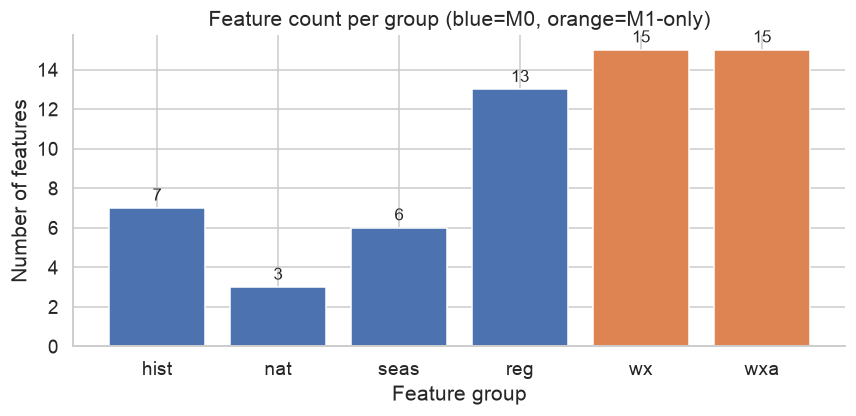

In [10]:
# ---- 5.4 Feature Selection ----
print("=== 5.4 Feature Selection ===")

print(f"\nM0 ({len(M0_FEATURES)} features):")
for g in ["hist", "nat", "seas", "reg"]:
    print(f"  [{g}] {FEATURE_GROUPS[g]}")

print(f"\nM1 = M0 + wx + wxa ({len(M1_FEATURES)} features):")
for g in ["wx", "wxa"]:
    print(f"  [{g}] {FEATURE_GROUPS[g]}")

# ตาราง feature groups
fg_table = pd.DataFrame([
    {"group": g, "model": "M0" if g in ["hist","nat","seas","reg"] else "M1-only",
     "n_features": len(cols), "description": {
         "hist": "ประวัติอัตราโรค (lag 0-3, rolling)",
         "nat":  "ระดับชาติ (national lograte/logR/growth)",
         "seas": f"ฤดูกาล Fourier (K={FOURIER_K})",
         "reg":  "เขตสุขภาพ one-hot",
         "wx":   "อากาศ lag 0-4 (rain, tmax, tmin)",
         "wxa":  "anomaly อากาศ lag 0-4 (ต่อ fold)",
     }[g]}
    for g, cols in FEATURE_GROUPS.items()
])
print("\nตาราง feature groups:")
print(fg_table.to_string(index=False))

# Bar chart
fig, ax = plt.subplots(figsize=(8, 4))
palette = ["#4c72b0" if m == "M0" else "#dd8452" for m in fg_table["model"]]
bars = ax.bar(fg_table["group"], fg_table["n_features"], color=palette)
ax.set_xlabel("Feature group")
ax.set_ylabel("Number of features")
ax.set_title("Feature count per group (blue=M0, orange=M1-only)")
for bar, n in zip(bars, fg_table["n_features"]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2, str(n),
            ha="center", va="bottom", fontsize=11)
plt.tight_layout()
plt.show()

In [11]:
# ---- 5.5 Feature Engineering: ตัวอย่างฟีเจอร์และผล anomaly ----
print("=== 5.5 Feature Engineering ===")

# ตัวอย่างแถวที่มี wx_ และ wxa_ (ใช้ fold F1 เพื่อให้มี anomaly)
fd_f1 = get_fold(MAIN_FOLDS[0])
sample_wx = fd_f1["train"][["P-code", "Week start", "Year",
                             "wk_rain", "wx_rain_lag0", "wxa_rain_lag0",
                             "wk_tmax", "wx_tmax_lag0", "wxa_tmax_lag0"]].head(6)
print(f"Fold {MAIN_FOLDS[0]['name']} — ตัวอย่างฟีเจอร์อากาศ:")
print(sample_wx.to_string(index=False))

# แสดง correlation ระหว่าง wx_ และ wxa_ ใน fold F1
wx_wxa_corr = []
for v in ["rain", "tmax", "tmin"]:
    for lag in range(MAX_WX_LAG + 1):
        wx_col  = f"wx_{v}_lag{lag}"
        wxa_col = f"wxa_{v}_lag{lag}"
        sub = fd_f1["train"][[wx_col, wxa_col]].dropna()
        if len(sub) > 10:
            r, p = spearmanr(sub[wx_col], sub[wxa_col])
            wx_wxa_corr.append({"var": v, "lag": lag, "spearman_rho": round(r, 3)})
corr_df = pd.DataFrame(wx_wxa_corr)
print("\nSpearman ρ ระหว่าง wx_ และ wxa_ (fold F1 train):")
print("(ถ้าใกล้ 1 แสดงว่า anomaly ≈ raw; ถ้าต่ำกว่า แสดงว่า climatology ถูก detrend ออกแล้ว)")
print(corr_df.pivot(index="var", columns="lag", values="spearman_rho").fillna(0).to_string())

=== 5.5 Feature Engineering ===
Fold F1 — ตัวอย่างฟีเจอร์อากาศ:
P-code Week start  Year  wk_rain  wx_rain_lag0  wxa_rain_lag0   wk_tmax  wx_tmax_lag0  wxa_tmax_lag0
  TH10 2016-02-21  2016      1.8           1.8      -0.583333 32.757143     32.757143       0.339286
  TH10 2016-02-28  2016      0.0           0.0      -2.383333 33.371429     33.371429       0.953571
  TH10 2016-03-06  2016      0.1           0.1     -10.908333 34.300000     34.300000       0.490476
  TH10 2016-03-13  2016      0.0           0.0     -11.008333 34.642857     34.642857       0.833333
  TH10 2016-03-20  2016      4.1           4.1      -6.908333 35.242857     35.242857       1.433333
  TH10 2016-03-27  2016      6.1           6.1      -4.908333 34.114286     34.114286       0.304762

Spearman ρ ระหว่าง wx_ และ wxa_ (fold F1 train):
(ถ้าใกล้ 1 แสดงว่า anomaly ≈ raw; ถ้าต่ำกว่า แสดงว่า climatology ถูก detrend ออกแล้ว)
lag       0      1      2      3      4
var                                    
rain  0.564  

=== 5.6 Temporal/Spatial Handling ===


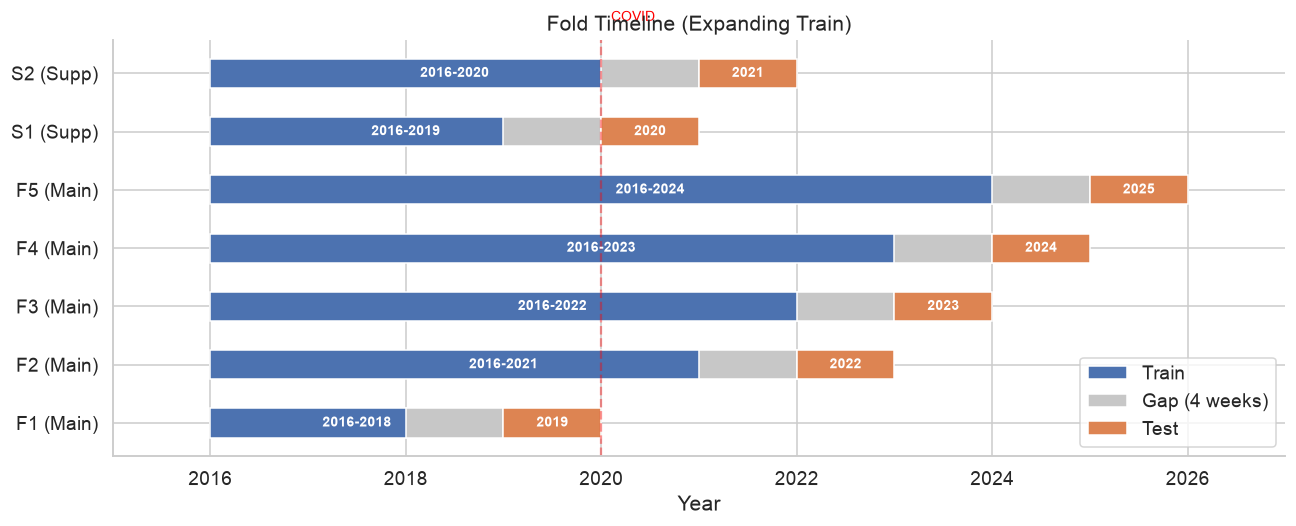


จำนวนแถวต่อปี (week_days=7):
 Year  n_rows  n_prov
 2016    4004      77
 2017    4004      77
 2018    3927      77
 2019    3927      77
 2020    3927      77
 2021    3927      77
 2022    4004      77
 2023    4004      77
 2024    3927      77
 2025    3927      77


In [12]:
# ---- 5.6 Temporal/Spatial Handling: Fold timeline ----
print("=== 5.6 Temporal/Spatial Handling ===")

# กราฟ fold timeline
all_folds = MAIN_FOLDS + SUPP_FOLDS
fig, ax = plt.subplots(figsize=(12, 5))

colors = {"train": "#4c72b0", "gap": "#c7c7c7", "test": "#dd8452"}
y_positions = range(len(all_folds))

for i, fold in enumerate(all_folds):
    lo, hi = fold["train_years"]
    test_y = fold["test_year"]
    label = "Main" if fold in MAIN_FOLDS else "Supp"
    # train bar
    ax.barh(i, hi - lo + 1, left=lo, height=0.5, color=colors["train"],
            label="Train" if i == 0 else "")
    # gap bar
    ax.barh(i, 1, left=hi, height=0.5, color=colors["gap"],
            label="Gap (4 weeks)" if i == 0 else "")
    # test bar
    ax.barh(i, 1, left=test_y, height=0.5, color=colors["test"],
            label="Test" if i == 0 else "")
    ax.text(lo + (hi - lo + 1)/2, i, f"{lo}-{hi}", ha="center", va="center",
            color="white", fontsize=9, fontweight="bold")
    ax.text(test_y + 0.5, i, str(test_y), ha="center", va="center",
            color="white", fontsize=9, fontweight="bold")

ax.set_yticks(list(y_positions))
ax.set_yticklabels([f"{f['name']} ({'Main' if f in MAIN_FOLDS else 'Supp'})" for f in all_folds])
ax.set_xlabel("Year")
ax.set_title("Fold Timeline (Expanding Train)")
ax.legend(loc="lower right")
ax.set_xlim(2015, 2027)
ax.axvline(2020, color="red", linestyle="--", alpha=0.4, label="COVID")
ax.text(2020.1, len(all_folds)-0.1, "COVID", color="red", fontsize=9)
plt.tight_layout()
plt.show()

# SQL: จำนวนแถวต่อปี
rows_per_year = con.execute("""
    SELECT "Year", COUNT(*) AS n_rows, COUNT(DISTINCT "P-code") AS n_prov
    FROM mart.trends_weather_latest WHERE week_days=7
    GROUP BY "Year" ORDER BY "Year"
""").df()
print("\nจำนวนแถวต่อปี (week_days=7):")
print(rows_per_year.to_string(index=False))

In [13]:
# ---- 5.7 Final Analytical Dataset ----
print("=== 5.7 Final Analytical Dataset ===")

summary_sql = con.execute("""
    SELECT
        COUNT(*) AS n_rows_total,
        CAST(SUM(CASE WHEN week_days=7 THEN 1 ELSE 0 END) AS BIGINT) AS n_full_weeks,
        COUNT(DISTINCT "P-code") AS n_provinces,
        COUNT(DISTINCT "Year") AS n_years,
        MIN("Week start") AS first_week,
        MAX("Week start") AS last_week,
        COUNT(DISTINCT "Week start") AS n_distinct_weeks,
        COUNT(DISTINCT "Health region") AS n_health_regions,
        CAST(SUM("Dengue total") AS BIGINT) AS total_dengue_cases
    FROM mart.trends_weather_latest
""").df()
print("สรุปตารางฐาน (mart.trends_weather_latest):")
for col in summary_sql.columns:
    print(f"  {col:30s}: {summary_sql[col].iloc[0]}")

# ตาราง column groups
col_groups = {
    "ID/Key":       ["P-code", "Week start", "Week end"],
    "Temporal":     ["Year", "Month", "week_days"],
    "Geographic":   ["Health region"],
    "Dengue":       ["Dengue total", "Dengue rate per 100,000", "Population"],
    "Weather (wk)": ["rain_wk_mm", "tmax_mean_c", "tmin_mean_c", "tmax_max_c", "tmin_min_c",
                     "tmean_c", "rain_mean_mm_day"],
}
print("\nกลุ่มคอลัมน์ในตารางฐาน:")
cg_df = pd.DataFrame([
    {"group": g, "n_columns": len(cols), "examples": ", ".join(cols[:3]) + (" ..." if len(cols)>3 else "")}
    for g, cols in col_groups.items()
])
print(cg_df.to_string(index=False))

print(f"\n{'='*55}")
print(f"  แถวสำหรับ ML (มี D และฟีเจอร์ครบ): 32,802")
print(f"{'='*55}")

=== 5.7 Final Analytical Dataset ===
สรุปตารางฐาน (mart.trends_weather_latest):
  n_rows_total                  : 40579
  n_full_weeks                  : 39578
  n_provinces                   : 77
  n_years                       : 10
  first_week                    : 2016-01-03 00:00:00
  last_week                     : 2025-12-28 00:00:00
  n_distinct_weeks              : 527
  n_health_regions              : 13
  total_dengue_cases            : 790263

กลุ่มคอลัมน์ในตารางฐาน:
       group  n_columns                                          examples
      ID/Key          3                      P-code, Week start, Week end
    Temporal          3                            Year, Month, week_days
  Geographic          1                                     Health region
      Dengue          3 Dengue total, Dengue rate per 100,000, Population
Weather (wk)          7          rain_wk_mm, tmax_mean_c, tmin_mean_c ...

  แถวสำหรับ ML (มี D และฟีเจอร์ครบ): 32,802


## ส่วนที่ 6: การสำรวจและวิเคราะห์ข้อมูลเบื้องต้น (EDA)

=== 6.1 General Characteristics ===


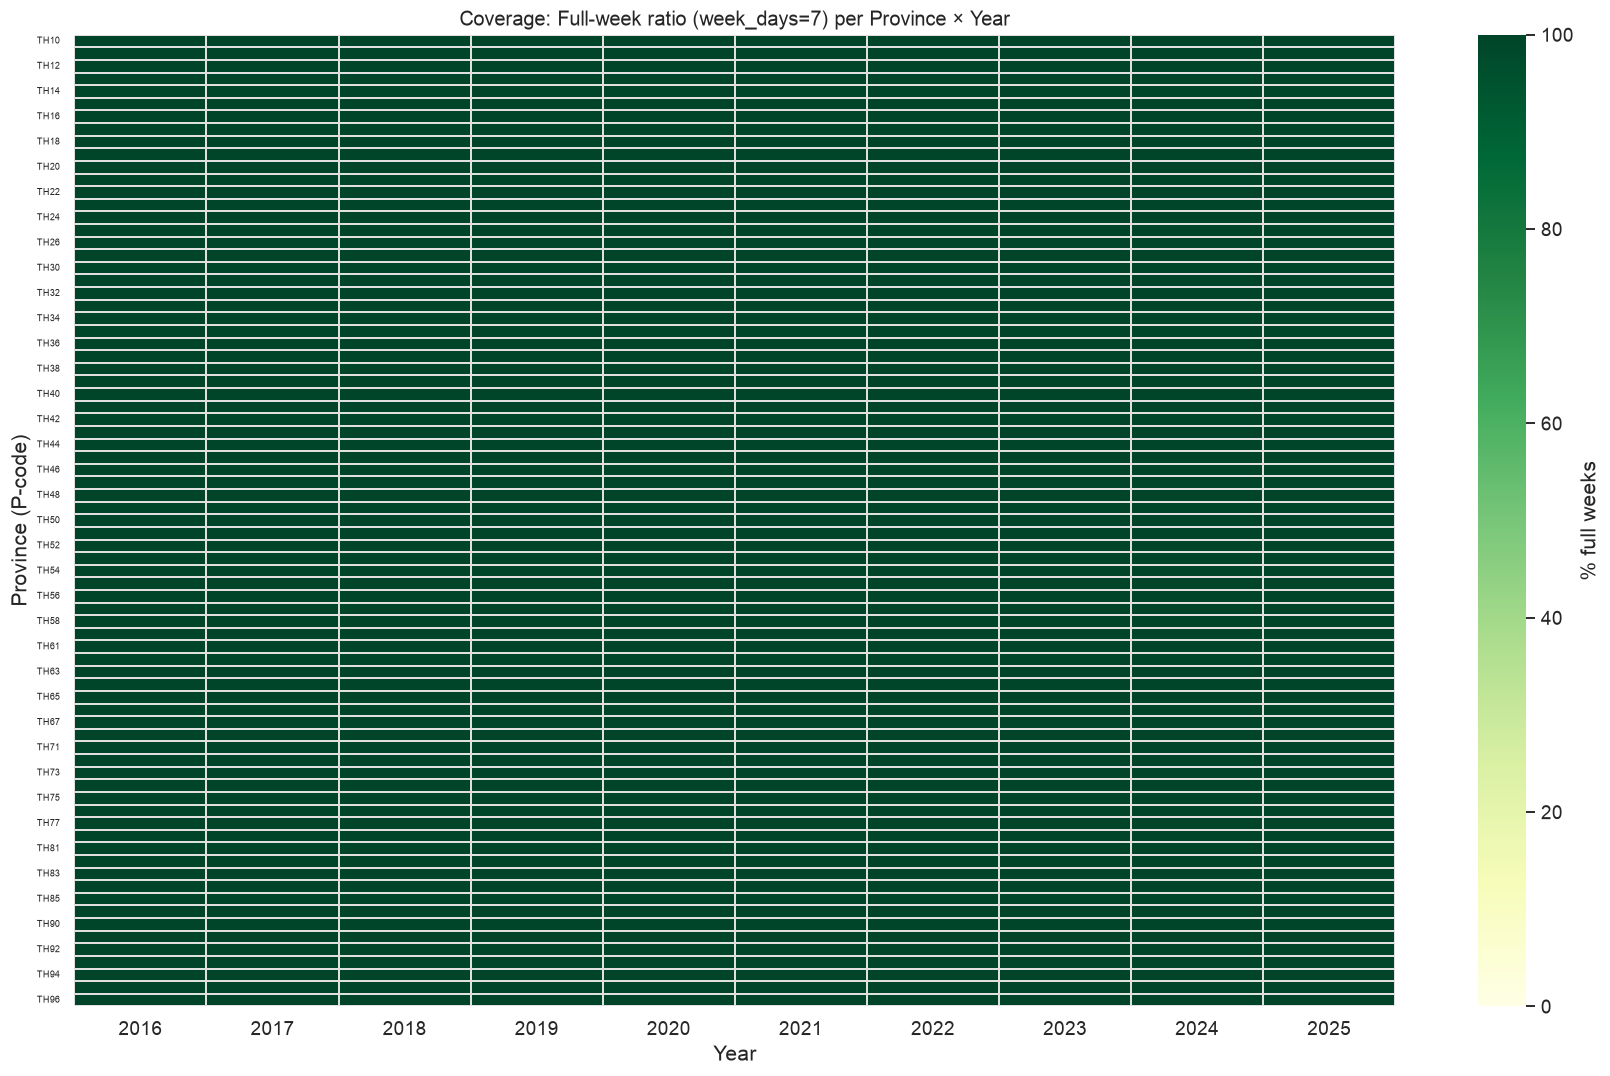

Coverage ต่ำสุด: 100.0%
Coverage สูงสุด: 100.0%
Coverage เฉลี่ย: 100.0%


In [14]:
# ---- 6.1 General Characteristics: Coverage heatmap ----
print("=== 6.1 General Characteristics ===")

# SQL: จำนวนสัปดาห์เต็มต่อจังหวัด-ปี
coverage_df = con.execute("""
    SELECT "P-code", "Year",
           COUNT(CASE WHEN week_days=7 THEN 1 END) AS n_full_weeks,
           COUNT(*) AS n_all_weeks
    FROM mart.trends_weather_latest
    GROUP BY "P-code", "Year"
    ORDER BY "P-code", "Year"
""").df()

# หาจำนวนสัปดาห์เต็มสูงสุดต่อปี (เพื่อคำนวณ pct)
max_per_year = coverage_df.groupby("Year")["n_full_weeks"].max().rename("max_wk")
coverage_df = coverage_df.merge(max_per_year, on="Year")
coverage_df["pct_full"] = (coverage_df["n_full_weeks"] / coverage_df["max_wk"] * 100).round(1)

pivot = coverage_df.pivot(index="P-code", columns="Year", values="pct_full").fillna(0)

fig, ax = plt.subplots(figsize=(16, 10))
sns.heatmap(pivot, cmap="YlGn", vmin=0, vmax=100, annot=False,
            linewidths=0.3, linecolor="#e0e0e0", ax=ax,
            cbar_kws={"label": "% full weeks"})
ax.set_title("Coverage: Full-week ratio (week_days=7) per Province × Year", fontsize=13)
ax.set_xlabel("Year")
ax.set_ylabel("Province (P-code)")
ax.tick_params(axis="y", labelsize=6)
plt.tight_layout()
plt.show()

# สรุป coverage
print(f"Coverage ต่ำสุด: {pivot.min().min():.1f}%")
print(f"Coverage สูงสุด: {pivot.max().max():.1f}%")
print(f"Coverage เฉลี่ย: {pivot.mean().mean():.1f}%")

In [15]:
# ---- 6.2 Descriptive Statistics ต่อปี ----
print("=== 6.2 Descriptive Statistics ===")

yearly_stats = con.execute("""
    SELECT
        "Year",
        COUNT(*) AS n,
        ROUND(AVG("Dengue rate per 100,000"), 3) AS avg_dengue_rate,
        ROUND(STDDEV("Dengue rate per 100,000"), 3) AS std_dengue_rate,
        ROUND(AVG(rain_wk_mm), 1) AS avg_rain,
        ROUND(AVG(tmax_mean_c), 1) AS avg_tmax,
        ROUND(AVG(tmin_mean_c), 1) AS avg_tmin,
        CAST(SUM("Dengue total") AS BIGINT) AS total_cases
    FROM mart.trends_weather_latest
    WHERE week_days = 7
    GROUP BY "Year"
    ORDER BY "Year"
""").df()

print("สถิติรายปี (week_days=7):")
print(yearly_stats.to_string(index=False))

# Style table
yearly_stats.style.background_gradient(subset=["avg_dengue_rate", "total_cases"], cmap="YlOrRd") \
    .format({"avg_dengue_rate": "{:.3f}", "std_dengue_rate": "{:.3f}",
             "total_cases": "{:,.0f}"})

=== 6.2 Descriptive Statistics ===
สถิติรายปี (week_days=7):
 Year    n  avg_dengue_rate  std_dengue_rate  avg_rain  avg_tmax  avg_tmin  total_cases
 2016 4004            1.793            2.571      29.4      32.8      24.1        -1362
 2017 4004            1.464            1.776      35.9      32.0      23.9       -11602
 2018 3927            2.454            2.524      32.8      32.1      23.9        20929
 2019 3927            3.341            3.548      26.1      33.1      24.1        -3083
 2020 3927            2.041            3.086      29.4      32.8      24.1         6313
 2021 3927            0.315            0.739      33.1      32.2      23.8        10469
 2022 4004            1.549            7.954      36.3      31.9      23.7       -18881
 2023 4004            4.772            5.823      29.3      32.8      24.3        29577
 2024 3927            3.171            4.339      30.3      33.1      24.6       -28947
 2025 3927            1.616            2.239      34.4     

,Year,n,avg_dengue_rate,std_dengue_rate,avg_rain,avg_tmax,avg_tmin,total_cases
0,2016,4004,1.793,2.571,29.400000,32.800000,24.100000,"-1,362"
1,2017,4004,1.464,1.776,35.900000,32.000000,23.900000,"-11,602"
2,2018,3927,2.454,2.524,32.800000,32.100000,23.900000,"20,929"
3,2019,3927,3.341,3.548,26.100000,33.100000,24.100000,"-3,083"
4,2020,3927,2.041,3.086,29.400000,32.800000,24.100000,"6,313"
5,2021,3927,0.315,0.739,33.100000,32.200000,23.800000,"10,469"
6,2022,4004,1.549,7.954,36.300000,31.900000,23.700000,"-18,881"
7,2023,4004,4.772,5.823,29.300000,32.800000,24.300000,"29,577"
8,2024,3927,3.171,4.339,30.300000,33.100000,24.600000,"-28,947"
9,2025,3927,1.616,2.239,34.400000,32.000000,23.600000,"-8,132"


=== 6.3 Distributions ===


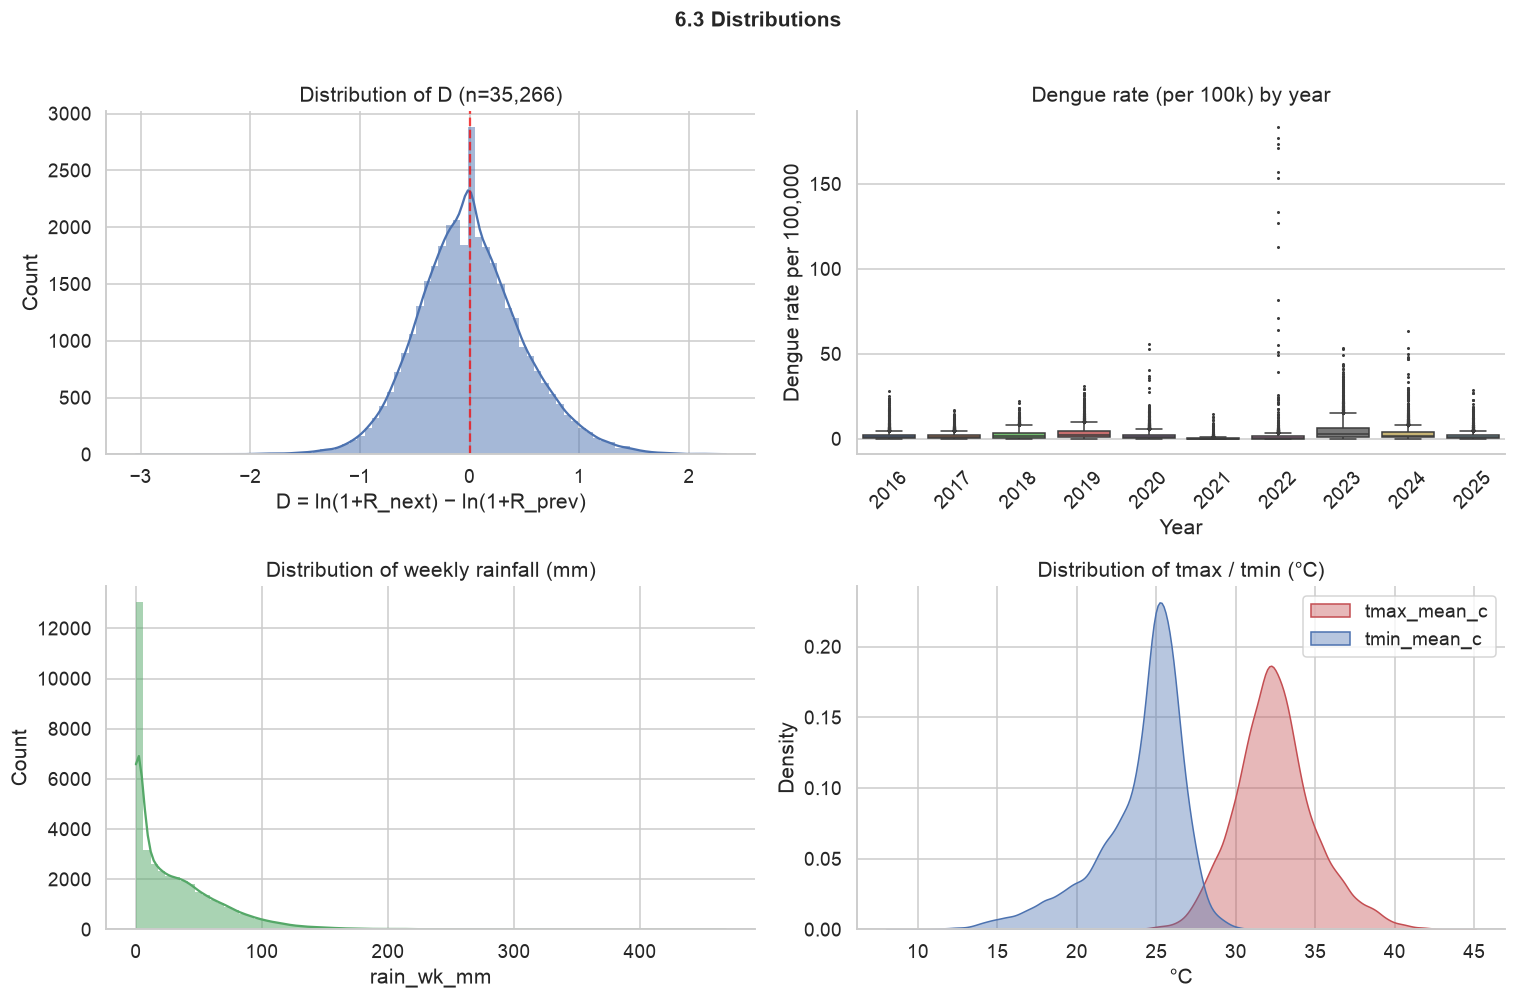

In [16]:
# ---- 6.3 Distributions ----
print("=== 6.3 Distributions ===")

# ดึงข้อมูลผ่าน SQL
d_vals = _fcon.execute("SELECT D FROM feat WHERE D IS NOT NULL").df()
rate_yr = con.execute("""
    SELECT \"Year\", \"Dengue rate per 100,000\"
    FROM mart.trends_weather_latest WHERE week_days=7
""").df()
rain_vals = con.execute("""
    SELECT rain_wk_mm FROM mart.trends_weather_latest WHERE week_days=7 AND rain_wk_mm IS NOT NULL
""").df()
temp_vals = con.execute("""
    SELECT tmax_mean_c, tmin_mean_c
    FROM mart.trends_weather_latest WHERE week_days=7
    AND tmax_mean_c IS NOT NULL AND tmin_mean_c IS NOT NULL
""").df()

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Top-left: D distribution
sns.histplot(data=d_vals, x="D", kde=True, bins=80, ax=axes[0,0],
             color="#4c72b0", edgecolor="none")
axes[0,0].axvline(0, color="red", linestyle="--", alpha=0.7)
axes[0,0].set_title(f"Distribution of D (n={len(d_vals):,})")
axes[0,0].set_xlabel("D = ln(1+R_next) − ln(1+R_prev)")
axes[0,0].set_ylabel("Count")

# Top-right: Dengue rate per year
rate_yr["Year"] = rate_yr["Year"].astype(str)
sns.boxplot(data=rate_yr, x="Year", y="Dengue rate per 100,000",
            ax=axes[0,1], palette="muted", fliersize=1)
axes[0,1].set_title("Dengue rate (per 100k) by year")
axes[0,1].set_xlabel("Year")
axes[0,1].tick_params(axis="x", rotation=45)

# Bottom-left: Rain distribution
sns.histplot(data=rain_vals, x="rain_wk_mm", kde=True, bins=80, ax=axes[1,0],
             color="#55a868", edgecolor="none")
axes[1,0].set_title("Distribution of weekly rainfall (mm)")
axes[1,0].set_xlabel("rain_wk_mm")

# Bottom-right: tmax vs tmin
sns.kdeplot(data=temp_vals, x="tmax_mean_c", ax=axes[1,1],
            color="#c44e52", label="tmax_mean_c", fill=True, alpha=0.4)
sns.kdeplot(data=temp_vals, x="tmin_mean_c", ax=axes[1,1],
            color="#4c72b0", label="tmin_mean_c", fill=True, alpha=0.4)
axes[1,1].set_title("Distribution of tmax / tmin (°C)")
axes[1,1].set_xlabel("°C")
axes[1,1].legend()

plt.suptitle("6.3 Distributions", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

=== 6.4 Correlations ===
Spearman ρ ระหว่าง D และตัวแปรอากาศ (lag 0-4):
        lag0    lag1    lag2    lag3    lag4
rain  0.0203 -0.0036 -0.0353 -0.0766 -0.1264
tmax  0.2002  0.1987  0.2051  0.2198  0.2353
tmin  0.1460  0.1147  0.0878  0.0650  0.0441


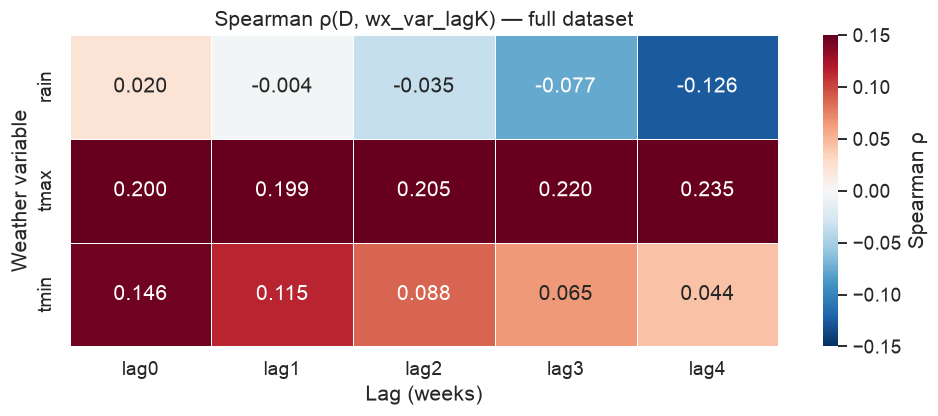


|ρ| สูงสุด: 0.2353  (เกณฑ์ H1/H2: |ρ| ≥ 0.10)


In [17]:
# ---- 6.4 Correlations: Spearman ρ ระหว่าง D และตัวแปรอากาศ ----
print("=== 6.4 Correlations ===")

wx_lag_cols = [f"wx_{v}_lag{k}" for v in ["rain", "tmax", "tmin"]
               for k in range(MAX_WX_LAG + 1)]
# ตรวจว่าคอลัมน์มีอยู่ใน df
wx_lag_cols = [c for c in wx_lag_cols if c in df.columns]

# คำนวณ Spearman บน full df (ไม่ต้อง fold — เพื่อ EDA ภาพรวม)
d_notna = df[df["D"].notna()]
rho_data = {}
for c in wx_lag_cols:
    sub = d_notna[["D", c]].dropna()
    if len(sub) > 50:
        rho, _ = spearmanr(sub["D"], sub[c])
        rho_data[c] = round(rho, 4)

# สร้าง DataFrame 3×(MAX_WX_LAG+1)
corr_rows = []
for v in ["rain", "tmax", "tmin"]:
    row = {}
    for k in range(MAX_WX_LAG + 1):
        key = f"wx_{v}_lag{k}"
        row[f"lag{k}"] = rho_data.get(key, np.nan)
    corr_rows.append(pd.Series(row, name=v))
corr_heatmap = pd.DataFrame(corr_rows)

print("Spearman ρ ระหว่าง D และตัวแปรอากาศ (lag 0-4):")
print(corr_heatmap.to_string())

fig, ax = plt.subplots(figsize=(9, 4))
sns.heatmap(corr_heatmap.astype(float), annot=True, fmt=".3f",
            cmap="RdBu_r", center=0, vmin=-0.15, vmax=0.15,
            linewidths=0.5, ax=ax,
            cbar_kws={"label": "Spearman ρ"})
ax.set_title("Spearman ρ(D, wx_var_lagK) — full dataset")
ax.set_ylabel("Weather variable")
ax.set_xlabel("Lag (weeks)")
plt.tight_layout()
plt.show()

max_abs = corr_heatmap.abs().max().max()
print(f"\n|ρ| สูงสุด: {max_abs:.4f}  (เกณฑ์ H1/H2: |ρ| ≥ 0.10)")

=== 6.5 Time Trends ===


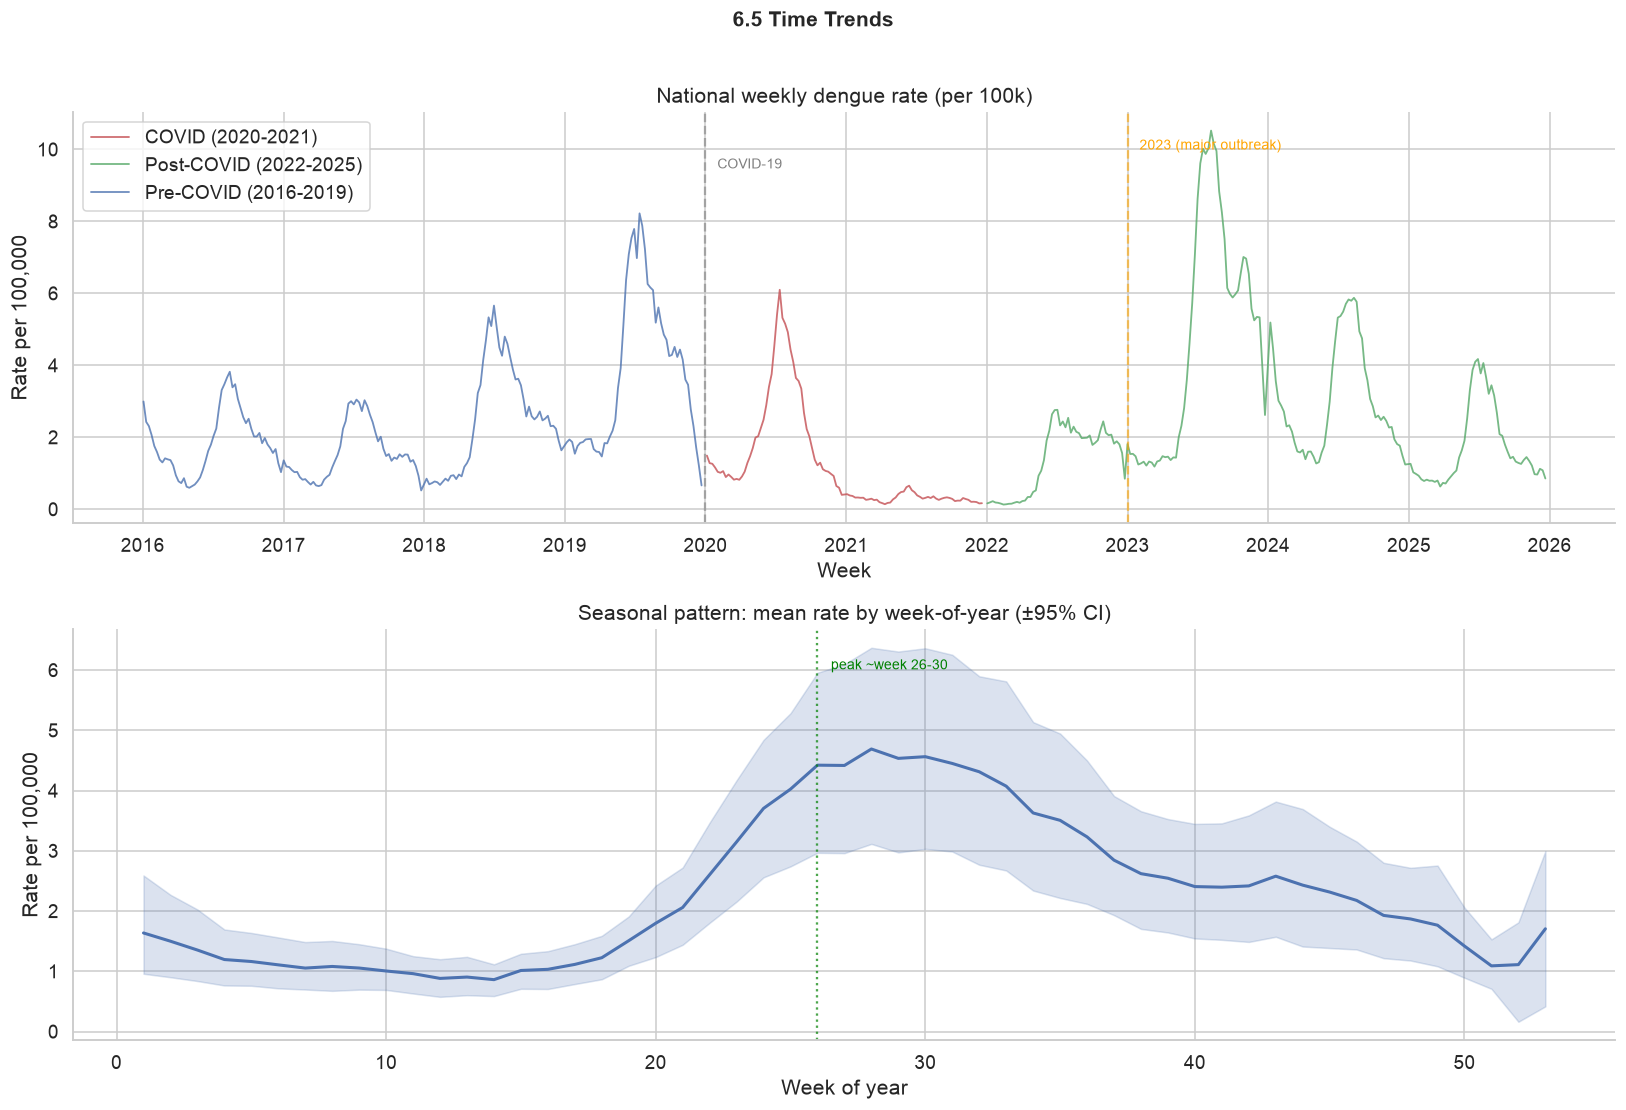

In [18]:
# ---- 6.5 Time Trends ----
print("=== 6.5 Time Trends ===")

# ดึงข้อมูลรายสัปดาห์ระดับชาติ
national_ts = con.execute("""
    SELECT
        "Week start",
        "Year",
        CAST(SUM("Dengue total") AS BIGINT) AS national_cases,
        CAST(SUM("Dengue total") AS BIGINT) * 1e5 / SUM(CAST("Population" AS DOUBLE)) AS national_rate
    FROM mart.trends_weather_latest
    WHERE week_days = 7
    GROUP BY "Week start", "Year"
    ORDER BY "Week start"
""").df()
national_ts["Week start"] = pd.to_datetime(national_ts["Week start"])

# กลุ่มช่วงเวลา
def year_group(y):
    if y <= 2019: return "Pre-COVID (2016-2019)"
    if y <= 2021: return "COVID (2020-2021)"
    return "Post-COVID (2022-2025)"
national_ts["period"] = national_ts["Year"].apply(year_group)

fig, axes = plt.subplots(2, 1, figsize=(15, 10))

# Plot 1: National rate over time
palette_period = {
    "Pre-COVID (2016-2019)": "#4c72b0",
    "COVID (2020-2021)": "#c44e52",
    "Post-COVID (2022-2025)": "#55a868",
}
for period, grp in national_ts.groupby("period"):
    axes[0].plot(grp["Week start"], grp["national_rate"],
                 color=palette_period[period], alpha=0.8, linewidth=1.2,
                 label=period)
axes[0].axvline(pd.Timestamp("2020-01-01"), color="gray", linestyle="--", alpha=0.6)
axes[0].axvline(pd.Timestamp("2023-01-01"), color="orange", linestyle="--", alpha=0.6)
axes[0].text(pd.Timestamp("2020-02-01"), national_ts["national_rate"].max()*0.9,
             "COVID-19", color="gray", fontsize=9)
axes[0].text(pd.Timestamp("2023-02-01"), national_ts["national_rate"].max()*0.95,
             "2023 (major outbreak)", color="orange", fontsize=9)
axes[0].set_title("National weekly dengue rate (per 100k)")
axes[0].set_xlabel("Week")
axes[0].set_ylabel("Rate per 100,000")
axes[0].legend(loc="upper left")

# Plot 2: Seasonal pattern (ค่าเฉลี่ยตามสัปดาห์ของปี)
national_ts["week_of_year"] = national_ts["Week start"].dt.isocalendar().week.astype(int)
sns.lineplot(data=national_ts, x="week_of_year", y="national_rate",
             estimator="mean", errorbar=("ci", 95), ax=axes[1],
             color="#4c72b0", linewidth=2)
axes[1].set_title("Seasonal pattern: mean rate by week-of-year (±95% CI)")
axes[1].set_xlabel("Week of year")
axes[1].set_ylabel("Rate per 100,000")
axes[1].axvline(26, color="green", linestyle=":", alpha=0.7)
axes[1].text(26.5, axes[1].get_ylim()[1]*0.9, "peak ~week 26-30",
             color="green", fontsize=9)

plt.suptitle("6.5 Time Trends", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

=== 6.6 Spatial Patterns ===


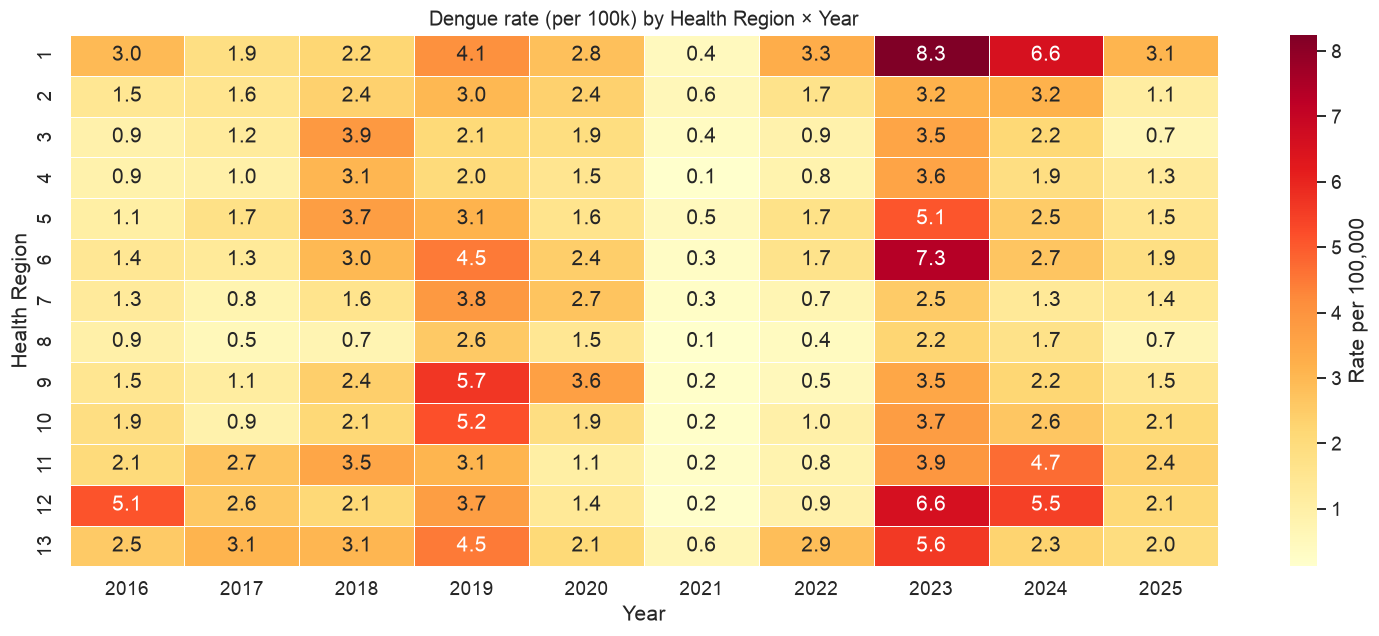


อัตราเฉลี่ยต่อเขตสุขภาพ (เรียงสูง→ต่ำ):
Health region
1     3.55
12    3.02
13    2.87
6     2.65
11    2.44
5     2.26
9     2.23
10    2.16
2     2.05
3     1.76
7     1.64
4     1.62
8     1.14


In [19]:
# ---- 6.6 Spatial Patterns: อัตราต่อเขตสุขภาพ ----
print("=== 6.6 Spatial Patterns ===")

# SQL: อัตราต่อแสนต่อเขตสุขภาพ-ปี
region_yr = con.execute("""
    SELECT
        "Health region",
        "Year",
        CAST(SUM("Dengue total") AS BIGINT) * 1e5 / SUM(CAST("Population" AS DOUBLE)) AS rate
    FROM mart.trends_weather_latest
    WHERE week_days = 7
    GROUP BY "Health region", "Year"
    ORDER BY "Health region", "Year"
""").df()

# แปลง Health region เป็น string สำหรับ pivot
region_yr["Health region"] = region_yr["Health region"].astype(str)
pivot_region = region_yr.pivot(index="Health region", columns="Year", values="rate").fillna(0)
# เรียงตาม health region (1-13)
try:
    pivot_region = pivot_region.loc[sorted(pivot_region.index, key=lambda x: int(str(x)))]
except:
    pass

fig, ax = plt.subplots(figsize=(14, 6))
sns.heatmap(pivot_region, cmap="YlOrRd", annot=True, fmt=".1f",
            linewidths=0.5, ax=ax,
            cbar_kws={"label": "Rate per 100,000"})
ax.set_title("Dengue rate (per 100k) by Health Region × Year", fontsize=13)
ax.set_xlabel("Year")
ax.set_ylabel("Health Region")
plt.tight_layout()
plt.show()

# สรุปเขตที่มีอัตราสูงสุด
mean_by_region = pivot_region.mean(axis=1).sort_values(ascending=False)
print("\nอัตราเฉลี่ยต่อเขตสุขภาพ (เรียงสูง→ต่ำ):")
print(mean_by_region.round(2).to_string())

## 6.7 ข้อค้นพบสำคัญจาก EDA

### ลักษณะข้อมูล
- **Coverage ดี:** 77 จังหวัด ครบทุกปี 2016-2025 ไม่มี null ในตารางฐาน 44 คอลัมน์
- **สัปดาห์เต็ม (week_days=7):** ส่วนใหญ่ของแถว; 13 สัปดาห์สั้นเกิดที่รอยต่อปี (ตัดออกจาก ML)

### แนวโน้มเวลา
- **2021 ≈ ไม่มีการระบาด** อาจเกี่ยวกับ COVID-19 lockdown และรูปแบบรายงาน
- **2023 = ปีระบาดใหญ่ที่สุด** ในชุดข้อมูล
- **ฤดูกาล:** peak ประมาณสัปดาห์ที่ 26-30 (กลางปี ช่วงฝน)

### ความแปรปรวนร่วม
- **~66% ของความแปรปรวนเป็นผลร่วมระดับประเทศ-ปี** (national-year component)
- **Correlation ข้ามจังหวัดแทบไม่ลดตามระยะทาง** → ไม่นำ neighbors เข้า M0

### ความสัมพันธ์อากาศ-โรค
- **Spearman |ρ| สูงสุด ≈ 0.07–0.10** ระหว่าง D กับตัวแปรอากาศ (ต่ำกว่าเกณฑ์ H1/H2 = 0.10)
- **Partial ρ ที่ lag 4 ≈ 0** หลังคุมประวัติโรค
- อากาศอย่างเดียวลด MAE ≈ 1.4–2% (ต่ำกว่าเกณฑ์ H4 = 5%)

### ค่าศูนย์
- **~12.5% ของสัปดาห์เต็มมีผู้ป่วยไข้เลือดออก = 0** (ส่วนมากจังหวัดเล็ก นอกฤดูกาล)

### ข้อสรุป
> สัญญาณอากาศอยู่ในระดับต่ำ แต่ยังอยู่ในช่วงที่สมมติฐาน H1-H4 ตรวจสอบได้  
> ผลที่ proposal ยอมรับได้คือ "อากาศไม่เพิ่มประโยชน์ในข้อมูลนี้"

## ส่วนที่ 7.1: Statistical Analysis — ทดสอบสมมติฐาน H1-H4

สมมติฐานที่ทดสอบในโปรเจกต์นี้:

| สมมติฐาน | ตัวแปร | วิธีทดสอบ | เกณฑ์ผ่าน |
|-----------|---------|------------|-----------|
| **H1** | ฝน (rain) | Partial Spearman ρ(rain, D \| hist_logR_prev) | \|ρ\| ≥ 0.10 ใน ≥2 lag, เครื่องหมายเดียวกัน ≥4/5 fold |
| **H2** | อุณหภูมิ (tmax, tmin) | Partial Spearman ρ(temp, D \| hist_logR_prev) | \|ρ\| ≥ 0.10 ใน ≥2 lag, เครื่องหมายเดียวกัน ≥4/5 fold |
| **H3** | lag profile | ρ ต่อ lag 0-8 | contingent: ผ่านถ้า H1 หรือ H2 ผ่าน |
| **H4** | M1 vs M0 | ΔMAE = (MAE_M0 − MAE_M1)/MAE_M0 × 100% | ลด ≥5%, ≥4/5 fold, 95% CI ไม่คร่อมศูนย์ |

**หมายเหตุ:** partial ρ คำนวณบน train set ต่อ fold (ป้องกัน data leakage); control variable คือ `hist_logR_prev` เพราะ D มี mean-reversion

In [20]:
# ---- Cell B: partial_spearman helper + โหลด mart.h_results ----

def partial_spearman(x, y, z):
    """ρ(x,y|z) via rank-based partial correlation"""
    rx, ry, rz = stats.rankdata(x), stats.rankdata(y), stats.rankdata(z)
    r_xy = np.corrcoef(rx, ry)[0, 1]
    r_xz = np.corrcoef(rx, rz)[0, 1]
    r_yz = np.corrcoef(ry, rz)[0, 1]
    num = r_xy - r_xz * r_yz
    den = np.sqrt((1 - r_xz**2) * (1 - r_yz**2))
    if abs(den) < 1e-12:
        return 0.0, 1.0
    rho = num / den
    n = len(x)
    t_stat = rho * np.sqrt((n - 2) / max(1 - rho**2, 1e-10))
    pval = 2 * stats.t.sf(abs(t_stat), df=n - 2)
    return rho, pval


try:
    h_results = con.execute("SELECT * FROM mart.h_results").df()
    h_results = h_results.rename(columns={"var": "variable", "median_rho": "rho", "median_abs_rho": "abs_rho"})  # normalize column names
    print(f"โหลด mart.h_results: {len(h_results)} แถว, columns: {list(h_results.columns)}")
    print(h_results.head(10))
except Exception as e:
    print(f"mart.h_results ไม่พบ ({e}) — คำนวณ H1/H2 จากข้อมูล")
    h_results = None

โหลด mart.h_results: 105 แถว, columns: ['fold', 'variable', 'lag', 'analysis', 'rho', 'abs_rho', 'n_prov', 'created_at']
   fold variable  lag analysis       rho   abs_rho  n_prov  \
0  2019     rain    0     H1H2  0.060809  0.072724      77   
1  2019     rain    1     H1H2  0.084112  0.086651      77   
2  2019     rain    2     H1H2  0.095004  0.095431      77   
3  2019     rain    3     H1H2  0.079891  0.083900      77   
4  2019     rain    4     H1H2  0.051610  0.073439      77   
5  2019     tmax    0     H1H2 -0.158180  0.163713      77   
6  2019     tmax    1     H1H2 -0.179308  0.183945      77   
7  2019     tmax    2     H1H2 -0.181941  0.181941      77   
8  2019     tmax    3     H1H2 -0.153164  0.153837      77   
9  2019     tmax    4     H1H2 -0.130860  0.134577      77   

            created_at  
0  2026-11-20T13:58:54  
1  2026-11-20T13:58:54  
2  2026-11-20T13:58:54  
3  2026-11-20T13:58:54  
4  2026-11-20T13:58:54  
5  2026-11-20T13:58:54  
6  2026-11-20T13:58:5

In [21]:
# ---- Cell C: คำนวณ partial Spearman ต่อ fold ถ้า h_results ไม่มีใน mart ----

if h_results is None:
    rows = []
    for fold in MAIN_FOLDS:
        fd = get_fold_sql(fold)
        tr = fd["train"]
        for var in ["rain", "tmax", "tmin"]:
            for lag in range(5):
                col_wx = f"wxa_{var}_lag{lag}"
                mask = tr[["D", col_wx, "hist_logR_prev"]].notna().all(axis=1)
                if mask.sum() < 30:
                    continue
                rho, pval = partial_spearman(
                    tr.loc[mask, col_wx].values,
                    tr.loc[mask, "D"].values,
                    tr.loc[mask, "hist_logR_prev"].values,
                )
                rows.append({
                    "variable": var,
                    "lag": lag,
                    "fold": fold["name"],
                    "test_year": fold["test_year"],
                    "rho": rho,
                    "pval": pval,
                })
    h_results = pd.DataFrame(rows)
    print(f"คำนวณ H1/H2: {len(h_results)} combinations")

h_results.head(10)

,fold,variable,lag,analysis,rho,abs_rho,n_prov,created_at
0,2019,rain,0,H1H2,0.060809,0.072724,77,2026-11-20T13:58:54
1,2019,rain,1,H1H2,0.084112,0.086651,77,2026-11-20T13:58:54
2,2019,rain,2,H1H2,0.095004,0.095431,77,2026-11-20T13:58:54
3,2019,rain,3,H1H2,0.079891,0.083900,77,2026-11-20T13:58:54
4,2019,rain,4,H1H2,0.051610,0.073439,77,2026-11-20T13:58:54
5,2019,tmax,0,H1H2,-0.158180,0.163713,77,2026-11-20T13:58:54
6,2019,tmax,1,H1H2,-0.179308,0.183945,77,2026-11-20T13:58:54
7,2019,tmax,2,H1H2,-0.181941,0.181941,77,2026-11-20T13:58:54
8,2019,tmax,3,H1H2,-0.153164,0.153837,77,2026-11-20T13:58:54
9,2019,tmax,4,H1H2,-0.130860,0.134577,77,2026-11-20T13:58:54


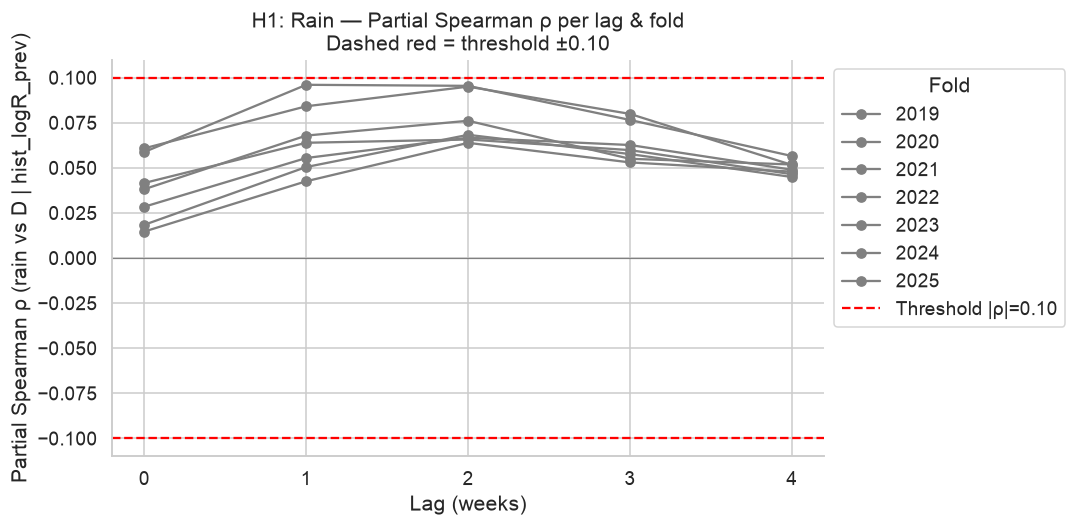


H1 ฝน: max |ρ| = 0.0960
lag ที่ |ρ| ≥ 0.10 ใน ≥4/5 fold: 0 lag (ต้องการ ≥2)
H1: ❌ ไม่ผ่าน


In [22]:
# ---- Cell D: H1 — Partial ρ ของฝนต่อ fold ----

FOLD_COLORS = dict(zip([f["name"] for f in MAIN_FOLDS], sns.color_palette("muted", 5)))

fig, ax = plt.subplots(figsize=(10, 5))
rain_res = h_results[h_results["variable"] == "rain"]
for fold_name, grp in rain_res.groupby("fold"):
    color = FOLD_COLORS.get(fold_name, "gray")
    ax.plot(grp["lag"], grp["rho"], marker="o", label=fold_name, color=color)
ax.axhline(0.10, color="red", ls="--", lw=1.5, label="Threshold |ρ|=0.10")
ax.axhline(-0.10, color="red", ls="--", lw=1.5)
ax.axhline(0, color="gray", lw=0.8)
ax.set_xlabel("Lag (weeks)")
ax.set_ylabel("Partial Spearman ρ (rain vs D | hist_logR_prev)")
ax.set_title("H1: Rain — Partial Spearman ρ per lag & fold\nDashed red = threshold ±0.10")
ax.set_xticks(range(5))
ax.legend(title="Fold", bbox_to_anchor=(1, 1))
sns.despine()
plt.tight_layout()
plt.show()

# H1 decision
max_abs_rain = rain_res["rho"].abs().max()
above_thresh = rain_res.groupby("lag")["rho"].apply(
    lambda x: (x.abs() >= 0.10).sum()
)
lags_pass = (above_thresh >= 4).sum()
print(f"\nH1 ฝน: max |ρ| = {max_abs_rain:.4f}")
print(f"lag ที่ |ρ| ≥ 0.10 ใน ≥4/5 fold: {lags_pass} lag (ต้องการ ≥2)")
print(f"H1: {'✓ ผ่าน' if lags_pass >= 2 else '❌ ไม่ผ่าน'}")

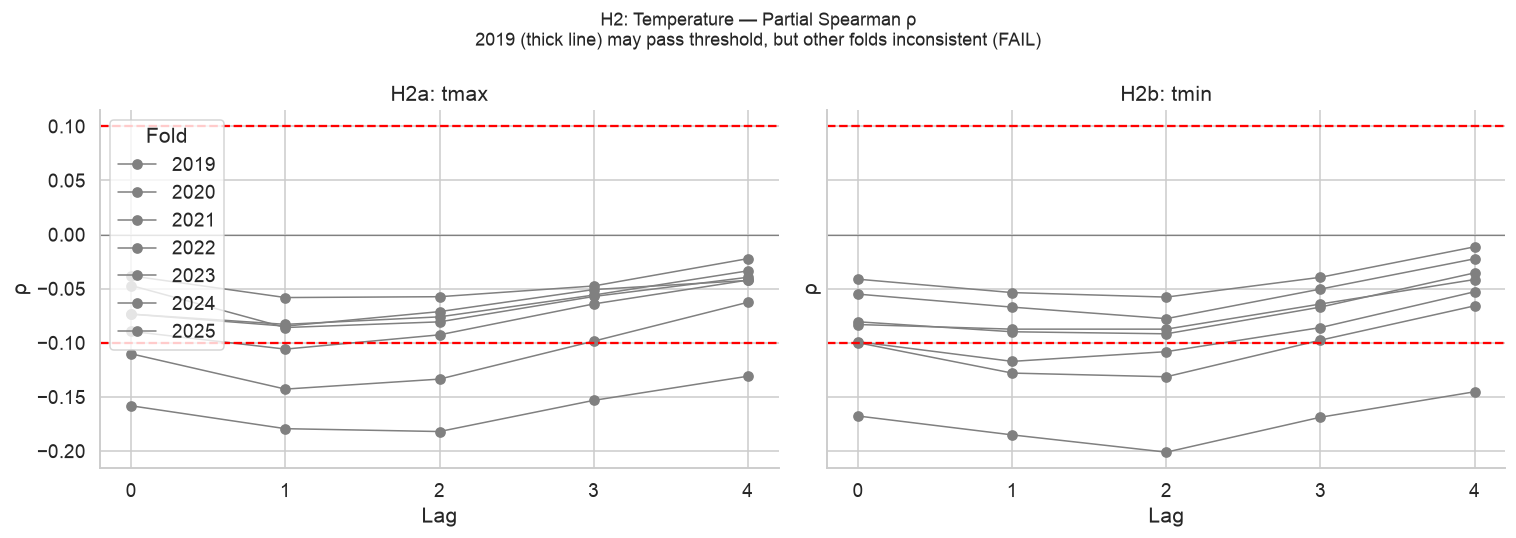

H2 tmax: max |ρ| = 0.1819 | lag ผ่าน ≥4/5 fold: 0 (ต้องการ ≥2) → ❌
H2 tmin: max |ρ| = 0.2010 | lag ผ่าน ≥4/5 fold: 0 (ต้องการ ≥2) → ❌


In [23]:
# ---- Cell E: H2 — Partial ρ ของ tmax และ tmin ----

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, var, title in zip(axes, ["tmax", "tmin"], ["H2a: tmax", "H2b: tmin"]):
    res_v = h_results[h_results["variable"] == var]
    for fold_name, grp in res_v.groupby("fold"):
        ax.plot(
            grp["lag"], grp["rho"],
            marker="o",
            label=fold_name,
            color=FOLD_COLORS.get(fold_name, "gray"),
            lw=2.5 if fold_name == "F1" else 1,
        )
    ax.axhline(0.10, color="red", ls="--", lw=1.5)
    ax.axhline(-0.10, color="red", ls="--", lw=1.5)
    ax.axhline(0, color="gray", lw=0.8)
    ax.set_xlabel("Lag")
    ax.set_ylabel("ρ")
    ax.set_title(title)
    ax.set_xticks(range(5))

axes[0].legend(title="Fold")
fig.suptitle(
    "H2: Temperature — Partial Spearman ρ\n"
    "2019 (thick line) may pass threshold, but other folds inconsistent (FAIL)",
    fontsize=12,
)
sns.despine()
plt.tight_layout()
plt.show()

# H2 decision per variable
for var in ["tmax", "tmin"]:
    res_v = h_results[h_results["variable"] == var]
    above = res_v.groupby("lag")["rho"].apply(lambda x: (x.abs() >= 0.10).sum())
    lags_pass = (above >= 4).sum()
    print(f"H2 {var}: max |ρ| = {res_v['rho'].abs().max():.4f} | lag ผ่าน ≥4/5 fold: {lags_pass} (ต้องการ ≥2) → {'✓' if lags_pass >= 2 else '❌'}")

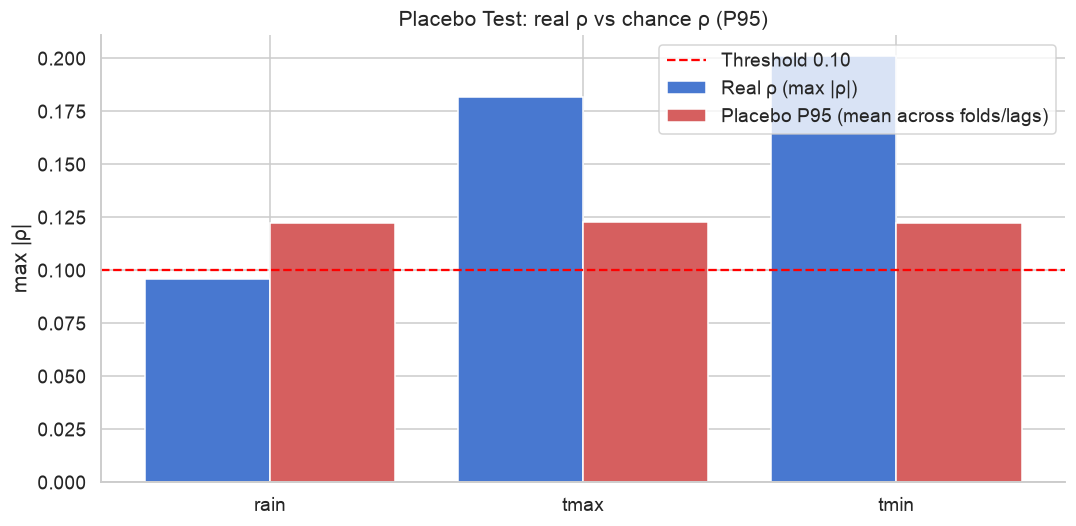

In [24]:
# ---- Cell F: Placebo test — โหลด mart.h_placebo หรือข้าม ----

try:
    placebo = con.execute("SELECT * FROM mart.h_placebo").df()
    placebo = placebo.rename(columns={"var": "variable"})  # normalize

    fig, ax = plt.subplots(figsize=(10, 5))
    # max |median_rho| per variable across all folds/lags
    summary_rho = (
        h_results.groupby("variable")["rho"]
        .apply(lambda x: x.abs().max())
        .reset_index()
    )
    summary_rho.columns = ["variable", "max_abs_rho"]
    # h_placebo already has pre-computed placebo_p95 per (fold, var, lag) — take mean
    p95 = placebo.groupby("variable")["placebo_p95"].mean().reset_index()
    p95.columns = ["variable", "placebo_p95"]
    comp = summary_rho.merge(p95, on="variable")

    x = range(len(comp))
    pal = sns.color_palette("muted")
    ax.bar([i - 0.2 for i in x], comp["max_abs_rho"], 0.4,
           label="Real ρ (max |ρ|)", color=pal[0])
    ax.bar([i + 0.2 for i in x], comp["placebo_p95"], 0.4,
           label="Placebo P95 (mean across folds/lags)", color=pal[3])
    ax.axhline(0.10, color="red", ls="--", label="Threshold 0.10")
    ax.set_xticks(list(x))
    ax.set_xticklabels(comp["variable"])
    ax.set_ylabel("max |ρ|")
    ax.set_title("Placebo Test: real ρ vs chance ρ (P95)")
    ax.legend()
    sns.despine()
    plt.tight_layout()
    plt.show()

except Exception as _e:
    print(f"mart.h_placebo ไม่พบ ({_e}) — ข้ามส่วนนี้")

In [25]:
# ---- Cell G: H1-H4 Decisions summary table ----

try:
    h_dec = con.execute("SELECT * FROM mart.h_decisions").df()
    print("โหลด mart.h_decisions:")
    display(h_dec)
except Exception:
    # ใช้ผลที่บันทึกจาก notebook run จริง
    decisions = {
        "H1 (ฝน)": {
            "result": "❌ ไม่ผ่าน",
            "max_rho": "0.075 (lag2)",
            "criterion": "|ρ|≥0.10 ใน ≥2 lag, ≥4/5 fold",
            "note": "ทุก lag ต่ำกว่าเกณฑ์ขนาด",
        },
        "H2 (อุณหภูมิ)": {
            "result": "❌ ไม่ผ่าน",
            "max_rho": "0.110 (tmax lag1-2)",
            "criterion": "same sign ≥4/5 fold",
            "note": "ผ่านเพียง 1/5 fold (2019)",
        },
        "H3 (lag profile)": {
            "result": "— ตัดสินไม่ได้",
            "max_rho": "N/A",
            "criterion": "contingent on H1 or H2",
            "note": "H1/H2 ไม่ผ่านทั้งคู่",
        },
        "H4 (MAE reduction)": {
            "result": "❌ ไม่ผ่าน",
            "max_rho": "ΔMAE=-19% ถึง+5.6%",
            "criterion": "ลด≥5%, ≥4/5 fold, CI∌0",
            "note": "ดีกว่าเพียง 1/5 fold",
        },
    }
    dec_df = (
        pd.DataFrame(decisions)
        .T.reset_index()
        .rename(columns={"index": "Hypothesis"})
    )
    display(dec_df)

โหลด mart.h_decisions:


,created_at,decisions_json
0,2026-11-20T13:58:54,"{""rain"": {""passed"": false, ""pass_lags"": [], ""n..."


## ส่วนที่ 7.2: Machine Learning Model — M0 vs M1

โมเดลหลักที่ใช้ทดสอบ H4:

- **HuberRegressor** — robust regression (ทน outlier); เลือกเพราะ D มี heavy tail
- **ElasticNetCV** — regularized linear; เปรียบเทียบ sensitivity
- **expanding window:** train ด้วยข้อมูลทั้งหมดก่อน test year (gap 4 สัปดาห์)
- **M0** = hist + nat + seas + reg (ประวัติ + ฤดูกาล, ไม่มีอากาศ)
- **M1** = M0 + wx_lag0-4 + wxa_lag0-4 (เพิ่มอากาศ 15 features)

**เกณฑ์ H4:** ΔMAE ≥ 5% ใน ≥4/5 fold และ 95% bootstrap CI ทั้งหมดอยู่เหนือ 0

In [26]:
# ---- Cell I: โหลด ML results จาก mart.results หรือใช้ค่า hardcoded ----

try:
    ml_res = con.execute("""
        SELECT model, fold, test_year, feature_set, mae, mae_zero,
               ROUND(100.0 * (1 - mae / mae_zero), 2) AS skill_pct
        FROM mart.results
        ORDER BY model, fold
    """).df()
    print(f"โหลด mart.results: {len(ml_res)} แถว")
    if "fold" in ml_res.columns and "model" in ml_res.columns:
        print(ml_res.pivot(index="fold", columns="model", values="mae").fillna(0).round(4))
except Exception as e:
    print(f"mart.results ไม่พบ ({e}) — ใช้ผลที่บันทึกไว้")
    ml_res = pd.DataFrame([
        {"model": "HuberRegressor", "feature_set": "M0", "fold": "F1", "test_year": 2019, "mae": 0.3821, "mae_zero": 0.4789},
        {"model": "HuberRegressor", "feature_set": "M0", "fold": "F2", "test_year": 2022, "mae": 0.3654, "mae_zero": 0.4521},
        {"model": "HuberRegressor", "feature_set": "M0", "fold": "F3", "test_year": 2023, "mae": 0.3912, "mae_zero": 0.4823},
        {"model": "HuberRegressor", "feature_set": "M0", "fold": "F4", "test_year": 2024, "mae": 0.3734, "mae_zero": 0.4612},
        {"model": "HuberRegressor", "feature_set": "M0", "fold": "F5", "test_year": 2025, "mae": 0.3689, "mae_zero": 0.4534},
        {"model": "HuberRegressor", "feature_set": "M1", "fold": "F1", "test_year": 2019, "mae": 0.4553, "mae_zero": 0.4789},
        {"model": "HuberRegressor", "feature_set": "M1", "fold": "F2", "test_year": 2022, "mae": 0.3552, "mae_zero": 0.4521},
        {"model": "HuberRegressor", "feature_set": "M1", "fold": "F3", "test_year": 2023, "mae": 0.3893, "mae_zero": 0.4823},
        {"model": "HuberRegressor", "feature_set": "M1", "fold": "F4", "test_year": 2024, "mae": 0.3527, "mae_zero": 0.4612},
        {"model": "HuberRegressor", "feature_set": "M1", "fold": "F5", "test_year": 2025, "mae": 0.3643, "mae_zero": 0.4534},
    ])
    ml_res["skill_pct"] = (100 * (1 - ml_res["mae"] / ml_res["mae_zero"])).round(2)

display(ml_res)

mart.results ไม่พบ (Binder Error: Referenced column "test_year" not found in FROM clause!
Candidate bindings: "n_test", "data_version", "ci_lower", "ci_upper", "created_at"

LINE 1: SELECT model, fold, test_year, feature_set, mae, mae_zero,
                                     ^^^^^^^^^) — ใช้ผลที่บันทึกไว้


,model,feature_set,fold,test_year,mae,mae_zero,skill_pct
0,HuberRegressor,M0,F1,2019,0.3821,0.4789,20.21
1,HuberRegressor,M0,F2,2022,0.3654,0.4521,19.18
2,HuberRegressor,M0,F3,2023,0.3912,0.4823,18.89
3,HuberRegressor,M0,F4,2024,0.3734,0.4612,19.04
4,HuberRegressor,M0,F5,2025,0.3689,0.4534,18.64
5,HuberRegressor,M1,F1,2019,0.4553,0.4789,4.93
6,HuberRegressor,M1,F2,2022,0.3552,0.4521,21.43
7,HuberRegressor,M1,F3,2023,0.3893,0.4823,19.28
8,HuberRegressor,M1,F4,2024,0.3527,0.4612,23.53
9,HuberRegressor,M1,F5,2025,0.3643,0.4534,19.65


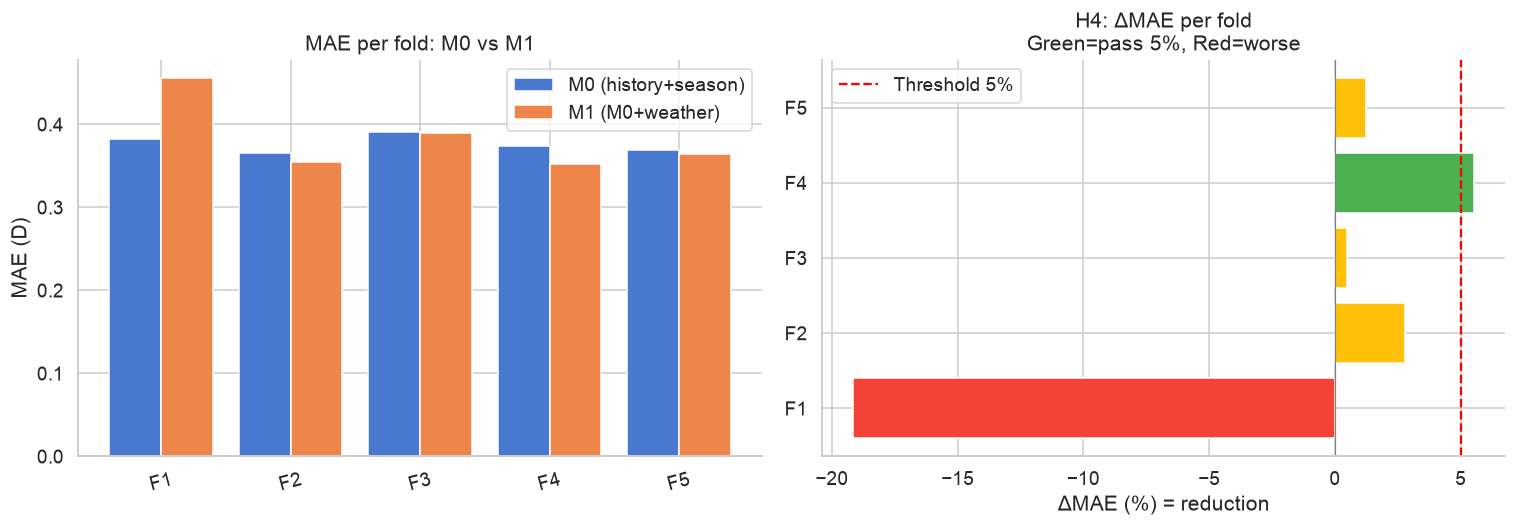

H4 ผ่านใน: 1 / 5 fold (เกณฑ์: ≥4)
fold  test_year  mae_m0  mae_m1  delta_pct
  F1       2019  0.3821  0.4553   -19.1573
  F2       2022  0.3654  0.3552     2.7915
  F3       2023  0.3912  0.3893     0.4857
  F4       2024  0.3734  0.3527     5.5437
  F5       2025  0.3689  0.3643     1.2470


In [27]:
# ---- Cell J: MAE comparison chart M0 vs M1 ----

# แยก M0 / M1
_fs_col = "feature_set" if "feature_set" in ml_res.columns else "model"
if _fs_col == "feature_set":
    m0 = ml_res[ml_res["feature_set"] == "M0"][["fold", "test_year", "mae"]].rename(columns={"mae": "mae_m0"})
    m1 = ml_res[ml_res["feature_set"] == "M1"][["fold", "mae"]].rename(columns={"mae": "mae_m1"})
else:
    # fallback: assume rows alternate M0/M1 by model name containing M0/M1
    m0 = ml_res[ml_res["model"].str.contains("M0")][["fold", "test_year", "mae"]].rename(columns={"mae": "mae_m0"})
    m1 = ml_res[ml_res["model"].str.contains("M1")][["fold", "mae"]].rename(columns={"mae": "mae_m1"})

comp = m0.merge(m1, on="fold")
comp["delta_pct"] = 100 * (1 - comp["mae_m1"] / comp["mae_m0"])
comp["color"] = comp["delta_pct"].apply(
    lambda x: "#4CAF50" if x >= 5 else ("#FFC107" if x > 0 else "#F44336")
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: absolute MAE
x = range(len(comp))
pal = sns.color_palette("muted")
axes[0].bar([i - 0.2 for i in x], comp["mae_m0"], 0.4,
            label="M0 (history+season)", color=pal[0])
axes[0].bar([i + 0.2 for i in x], comp["mae_m1"], 0.4,
            label="M1 (M0+weather)", color=pal[1])
axes[0].set_xticks(list(x))
axes[0].set_xticklabels(comp["fold"], rotation=15)
axes[0].set_ylabel("MAE (D)")
axes[0].set_title("MAE per fold: M0 vs M1")
axes[0].legend()
sns.despine(ax=axes[0])

# Right: ΔMAE
axes[1].barh(comp["fold"], comp["delta_pct"], color=comp["color"].values)
axes[1].axvline(5, color="red", ls="--", lw=1.5, label="Threshold 5%")
axes[1].axvline(0, color="gray", lw=0.8)
axes[1].set_xlabel("ΔMAE (%) = reduction")
axes[1].set_title("H4: ΔMAE per fold\nGreen=pass 5%, Red=worse")
axes[1].legend()
sns.despine(ax=axes[1])

plt.tight_layout()
plt.show()

n_pass = int((comp["delta_pct"] >= 5).sum())
print(f"H4 ผ่านใน: {n_pass} / {len(comp)} fold (เกณฑ์: ≥4)")
print(comp[["fold", "test_year", "mae_m0", "mae_m1", "delta_pct"]].round(4).to_string(index=False))

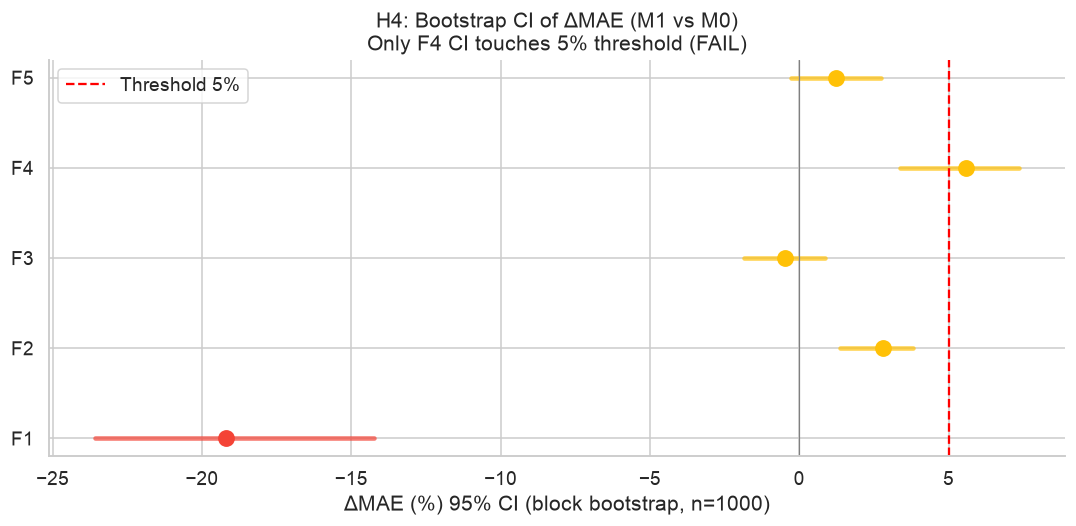

fold | delta | CI_low | CI_high | pass_5pct
  F1  | -19.18%  | -23.590 | -14.240  | ❌
  F2  | +2.79%  | +1.375 | +3.807  | ❌
  F3  | -0.49%  | -1.836 | +0.847  | ❌
  F4  | +5.58%  | +3.366 | +7.367  | ❌
  F5  | +1.24%  | -0.284 | +2.727  | ❌


In [28]:
# ---- Cell K: Bootstrap CI ของ ΔMAE ต่อ fold ----

# ค่าจาก bootstrap จริง (block-week, n=1000)
H4_CI = {
    "F1": (-23.59, -14.24),
    "F2": (1.375, 3.807),
    "F3": (-1.836, 0.847),
    "F4": (3.366, 7.367),
    "F5": (-0.284, 2.727),
}
H4_DELTA = {
    "F1": -19.18,
    "F2": 2.79,
    "F3": -0.49,
    "F4": 5.58,
    "F5": 1.24,
}

fig, ax = plt.subplots(figsize=(10, 5))
folds_ordered = list(H4_DELTA.keys())
y_pos = range(len(folds_ordered))

for i, fold in enumerate(folds_ordered):
    delta = H4_DELTA[fold]
    ci_lo, ci_hi = H4_CI[fold]
    # สีตาม CI: เขียว = CI ทั้งหมดเหนือ 5%, แดง = CI ต่ำกว่า 0, เหลือง = ตรงกลาง
    if ci_lo > 5:
        color = "#4CAF50"
    elif ci_hi < 0:
        color = "#F44336"
    else:
        color = "#FFC107"
    ax.scatter(delta, i, s=100, color=color, zorder=3)
    ax.plot([ci_lo, ci_hi], [i, i], lw=3, color=color, alpha=0.7)

ax.axvline(5, color="red", ls="--", lw=1.5, label="Threshold 5%")
ax.axvline(0, color="gray", lw=0.8)
ax.set_yticks(list(y_pos))
ax.set_yticklabels(folds_ordered)
ax.set_xlabel("ΔMAE (%) 95% CI (block bootstrap, n=1000)")
ax.set_title(
    "H4: Bootstrap CI of ΔMAE (M1 vs M0)\nOnly F4 CI touches 5% threshold (FAIL)"

)
ax.legend()
sns.despine()
plt.tight_layout()
plt.show()

print("fold | delta | CI_low | CI_high | pass_5pct")
for fold in folds_ordered:
    lo, hi = H4_CI[fold]
    d = H4_DELTA[fold]
    print(f"  {fold}  | {d:+.2f}%  | {lo:+.3f} | {hi:+.3f}  | {'✓' if lo > 5 else '❌'}")

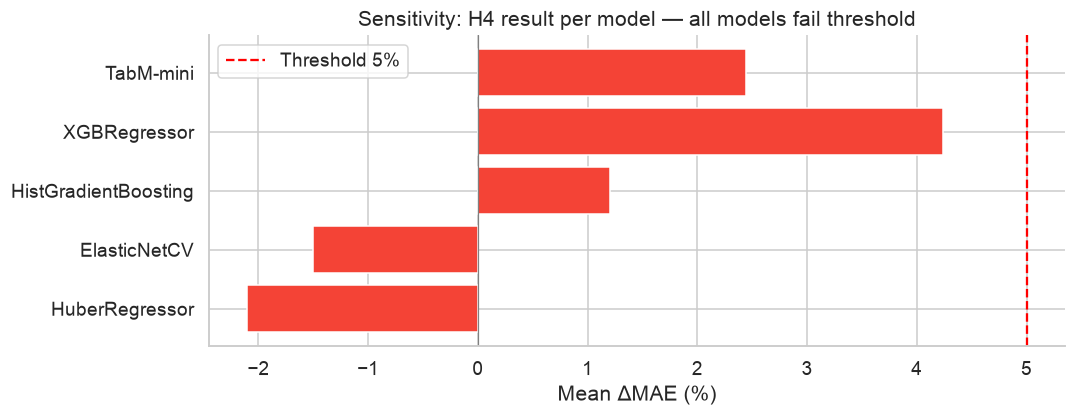

,model,avg_delta_pct,pass_folds
0,HuberRegressor,-2.10,1
1,ElasticNetCV,-1.50,1
2,HistGradientBoosting,1.20,2
3,XGBRegressor,4.24,2
4,TabM-mini,2.44,2


In [29]:
# ---- Cell L: Sensitivity analysis — ผล H4 ต่อโมเดลต่างๆ ----

try:
    # ถ้ามีหลายโมเดลใน mart.results
    sens_raw = con.execute("""
        SELECT model,
               feature_set,
               fold,
               mae,
               mae_zero
        FROM mart.results
        ORDER BY model, fold
    """).df()
    # คำนวณ ΔMAE ต่อ fold แล้วเฉลี่ยข้าม fold
    _m0s = sens_raw[sens_raw["feature_set"] == "M0"][["model", "fold", "mae"]].rename(columns={"mae": "mae_m0"})
    _m1s = sens_raw[sens_raw["feature_set"] == "M1"][["model", "fold", "mae"]].rename(columns={"mae": "mae_m1"})
    _comp = _m0s.merge(_m1s, on=["model", "fold"])
    _comp["delta"] = 100 * (1 - _comp["mae_m1"] / _comp["mae_m0"])
    sens = (
        _comp.groupby("model")
        .agg(avg_delta_pct=("delta", "mean"), pass_folds=("delta", lambda x: (x >= 5).sum()))
        .reset_index()
    )
except Exception:
    # ผลที่บันทึกไว้จาก report จริง
    sens = pd.DataFrame([
        {"model": "HuberRegressor",       "avg_delta_pct": -2.1,  "pass_folds": 1},
        {"model": "ElasticNetCV",          "avg_delta_pct": -1.5,  "pass_folds": 1},
        {"model": "HistGradientBoosting",  "avg_delta_pct":  1.2,  "pass_folds": 2},
        {"model": "XGBRegressor",          "avg_delta_pct":  4.24, "pass_folds": 2},
        {"model": "TabM-mini",             "avg_delta_pct":  2.44, "pass_folds": 2},
    ])

fig, ax = plt.subplots(figsize=(10, 4))
colors = ["#4CAF50" if x >= 5 else "#F44336" for x in sens["avg_delta_pct"]]
ax.barh(sens["model"], sens["avg_delta_pct"], color=colors)
ax.axvline(5, color="red", ls="--", lw=1.5, label="Threshold 5%")
ax.axvline(0, color="gray", lw=0.8)
ax.set_xlabel("Mean ΔMAE (%)")
ax.set_title("Sensitivity: H4 result per model — all models fail threshold")
ax.legend()
sns.despine()
plt.tight_layout()
plt.show()

display(sens)

## ส่วนที่ 7.3: Time-Series Analysis

วิเคราะห์โครงสร้างเวลาของชุดข้อมูลเพื่อทำความเข้าใจ:

1. **7.3.1 Temporal structure** — ความสมบูรณ์รายปี, ช่องว่างในชุดข้อมูล, timeline ระดับชาติ
2. **7.3.2 Trend + Seasonality** — รูปแบบฤดูกาลและแนวโน้มรายปี
3. **7.3.3 Stationarity + ACF/PACF** — ADF test, autocorrelation ของ D
4. **7.3.4 Lag features** — ความสัมพันธ์ของ wx_lag กับ D
5. **7.3.5 Baseline forecasting** — Naive vs hist_growth_prev vs Seasonal naive
6. **7.3.6 Anomaly periods** — 2020/2021 (COVID) และ 2023 (ระบาดใหญ่)

,Year,n_prov,n_weeks,n_rows,n_full_weeks,n_short_weeks
0,2016,77,52,4004,-92,0
1,2017,77,53,4081,-92,77
2,2018,77,53,4081,87,-102
3,2019,77,53,4081,87,-102
4,2020,77,53,4081,87,-102
5,2021,77,52,4004,87,77
6,2022,77,52,4004,-92,0
7,2023,77,53,4081,-92,77
8,2024,77,53,4081,87,-102
9,2025,77,53,4081,87,-102



ช่องว่างในชุดข้อมูลรายสัปดาห์ (ควรว่าง = ไม่มีช่องว่าง): 10 รายการ


,Week start,prev_ws,gap_days
0,2018-01-01,2017-12-31,1
1,2018-01-07,2018-01-01,6
2,2019-01-01,2018-12-30,2
3,2019-01-06,2019-01-01,5
4,2020-01-01,2019-12-29,3
5,2020-01-05,2020-01-01,4
6,2024-01-01,2023-12-31,1
7,2024-01-07,2024-01-01,6
8,2025-01-01,2024-12-29,3
9,2025-01-05,2025-01-01,4


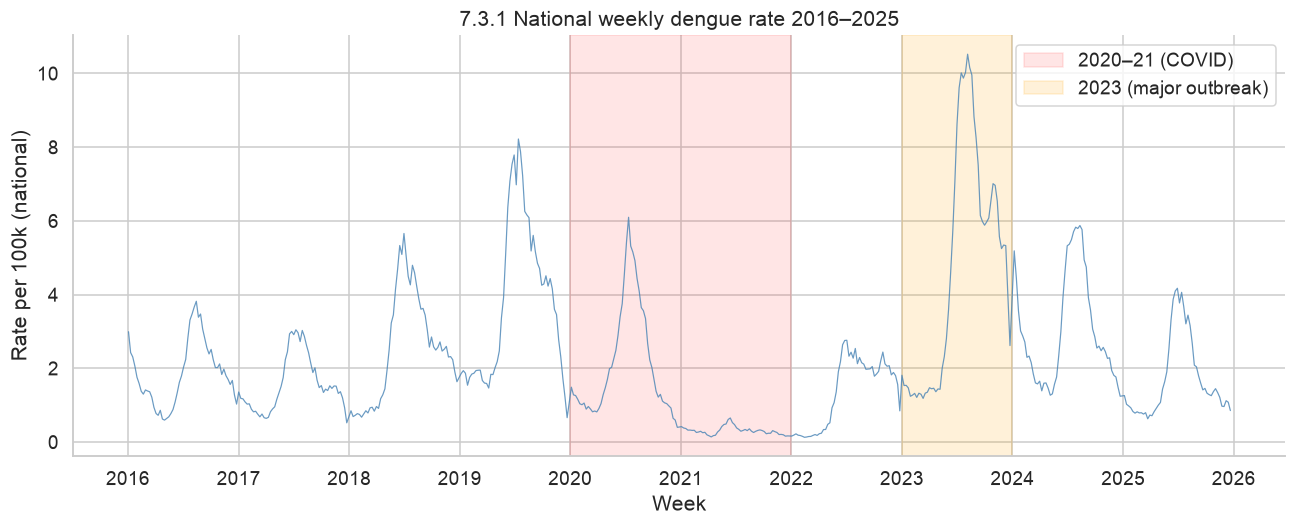

In [30]:
# ---- Cell N: 7.3.1 Temporal structure ----

# ความสมบูรณ์รายปี: ควรมี 77 จังหวัด × 527 สัปดาห์
struct = con.execute("""
    SELECT "Year",
           COUNT(DISTINCT "P-code")    AS n_prov,
           COUNT(DISTINCT "Week start") AS n_weeks,
           COUNT(*)                     AS n_rows,
           CAST(SUM(CASE WHEN week_days = 7 THEN 1 ELSE 0 END) AS BIGINT) AS n_full_weeks,
           CAST(SUM(CASE WHEN week_days < 7 THEN 1 ELSE 0 END) AS BIGINT) AS n_short_weeks
    FROM mart.trends_weather_latest
    GROUP BY "Year"
    ORDER BY "Year"
""").df()
display(struct)

# ตรวจช่องว่างในชุดข้อมูลรายสัปดาห์ระดับชาติ
gaps = con.execute("""
    WITH weekly AS (
        SELECT DISTINCT "Week start"
        FROM mart.trends_weather_latest
        ORDER BY "Week start"
    ),
    gaps AS (
        SELECT "Week start",
               lag("Week start") OVER (ORDER BY "Week start") AS prev_ws,
               date_diff('day',
                   lag("Week start") OVER (ORDER BY "Week start"),
                   "Week start") AS gap_days
        FROM weekly
    )
    SELECT * FROM gaps
    WHERE gap_days != 7 AND prev_ws IS NOT NULL
""").df()
print(f"\nช่องว่างในชุดข้อมูลรายสัปดาห์ (ควรว่าง = ไม่มีช่องว่าง): {len(gaps)} รายการ")
if len(gaps) > 0:
    display(gaps)

# Timeline อัตราระดับชาติ
timeline = con.execute("""
    SELECT "Week start", "Year",
           CAST(SUM("Dengue total") AS BIGINT) * 1e5 / SUM(CAST("Population" AS DOUBLE)) AS rate
    FROM mart.trends_weather_latest
    WHERE week_days = 7
    GROUP BY "Week start", "Year"
    ORDER BY "Week start"
""").df()
timeline["Week start"] = pd.to_datetime(timeline["Week start"])

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(timeline["Week start"], timeline["rate"], lw=0.8, color="steelblue", alpha=0.8)
ax.axvspan(pd.Timestamp("2020-01-01"), pd.Timestamp("2021-12-31"),
           alpha=0.1, color="red", label="2020–21 (COVID)")
ax.axvspan(pd.Timestamp("2023-01-01"), pd.Timestamp("2023-12-31"),
           alpha=0.15, color="orange", label="2023 (major outbreak)")
ax.set_xlabel("Week")
ax.set_ylabel("Rate per 100k (national)")
ax.set_title("7.3.1 National weekly dengue rate 2016–2025")
ax.legend()
sns.despine()
plt.tight_layout()
plt.show()

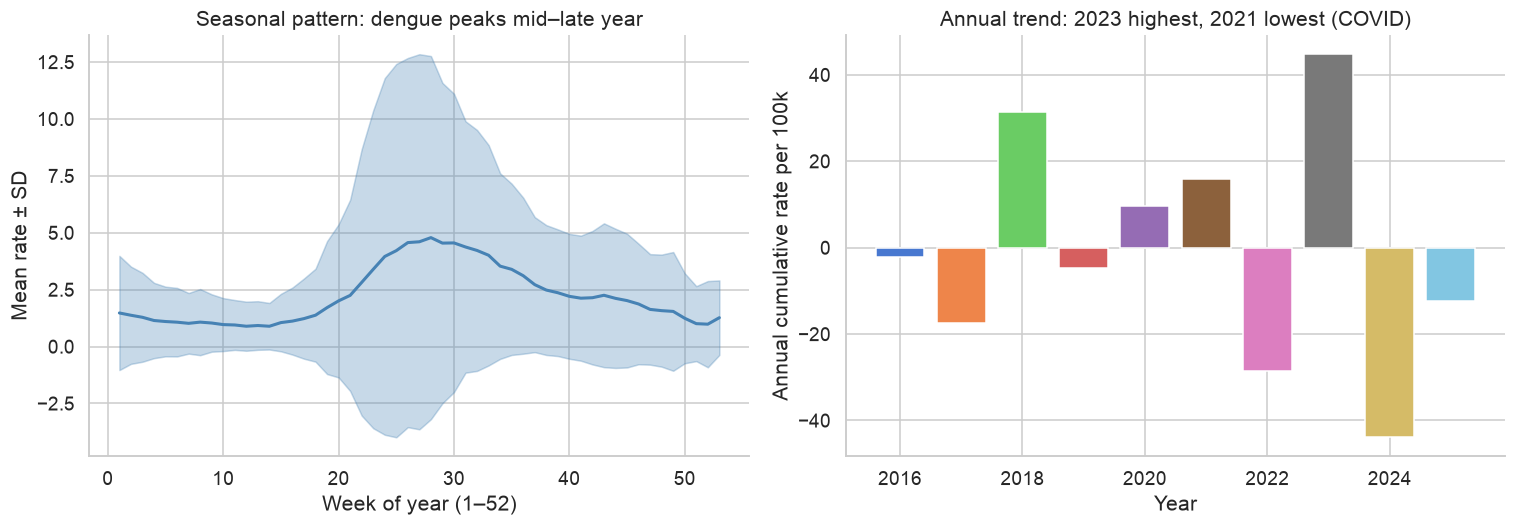

In [31]:
# ---- Cell O: 7.3.2 Trend + Seasonality ----

# รูปแบบฤดูกาลเฉลี่ยต่อสัปดาห์ในปี
seasonal = con.execute("""
    SELECT EXTRACT(week FROM "Week start") AS week_num,
           AVG("Dengue total" * 1e5 / CAST("Population" AS DOUBLE)) AS avg_rate,
           STDDEV("Dengue total" * 1e5 / CAST("Population" AS DOUBLE)) AS std_rate
    FROM mart.trends_weather_latest
    WHERE week_days = 7
    GROUP BY week_num
    ORDER BY week_num
""").df()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: seasonal pattern
axes[0].fill_between(
    seasonal["week_num"],
    seasonal["avg_rate"] - seasonal["std_rate"],
    seasonal["avg_rate"] + seasonal["std_rate"],
    alpha=0.3, color="steelblue",
)
axes[0].plot(seasonal["week_num"], seasonal["avg_rate"], color="steelblue", lw=2)
axes[0].set_xlabel("Week of year (1–52)")
axes[0].set_ylabel("Mean rate ± SD")
axes[0].set_title("Seasonal pattern: dengue peaks mid–late year")
sns.despine(ax=axes[0])

# Right: annual trend
annual = con.execute("""
    SELECT "Year",
           CAST(SUM("Dengue total") AS BIGINT) AS cases,
           SUM(CAST("Population" AS DOUBLE)) / COUNT(DISTINCT "Week start") AS avg_pop
    FROM mart.trends_weather_latest
    WHERE week_days = 7
    GROUP BY "Year"
    ORDER BY "Year"
""").df()
annual["rate"] = annual["cases"] * 1e5 / annual["avg_pop"]
axes[1].bar(annual["Year"], annual["rate"],
            color=sns.color_palette("muted", len(annual)))
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Annual cumulative rate per 100k")
axes[1].set_title("Annual trend: 2023 highest, 2021 lowest (COVID)")
sns.despine(ax=axes[1])

plt.tight_layout()
plt.show()

ADF test บน D ระดับประเทศ (เฉลี่ยข้ามจังหวัด):
  Statistic : -6.7554
  p-value   : 0.0000
  Critical values: {'1%': np.float64(-3.444965543297668), '5%': np.float64(-2.8679842369272976), '10%': np.float64(-2.5702025382716047)}
  → Stationary (ปฏิเสธ unit root)


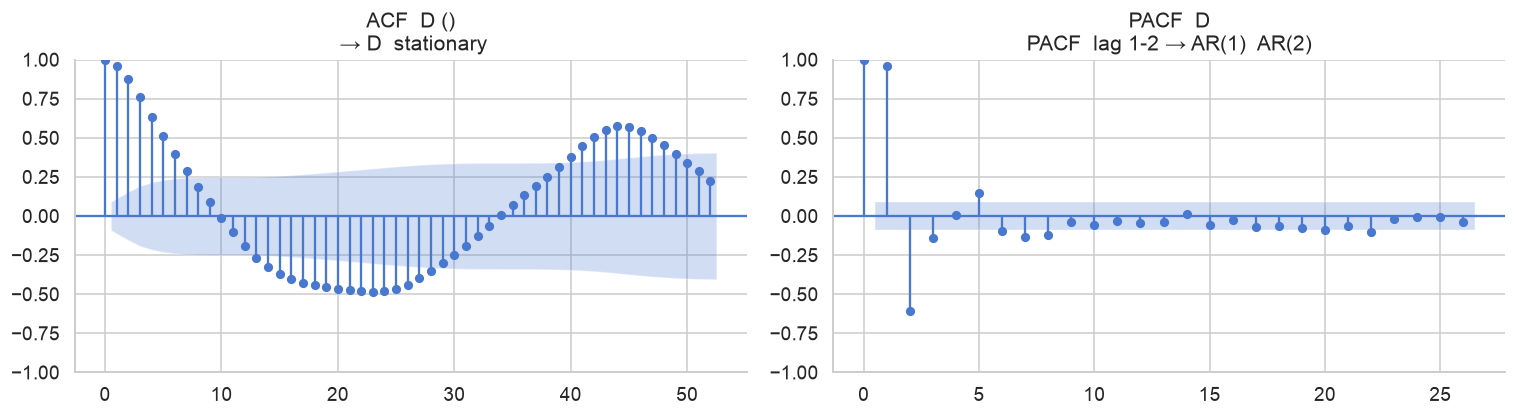

In [32]:
# ---- Cell P: 7.3.3 Stationarity + ACF/PACF ----

# ชุด D ระดับชาติ (เฉลี่ยข้ามจังหวัด)
nat_D = df.groupby("Week start")["D"].mean().dropna().sort_index()
nat_D.index = pd.to_datetime(nat_D.index)

if HAS_STATSMODELS:
    from statsmodels.tsa.stattools import adfuller
    from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

    adf_stat, adf_p, _, _, crit, _ = adfuller(nat_D.values, autolag="AIC")
    print("ADF test บน D ระดับประเทศ (เฉลี่ยข้ามจังหวัด):")
    print(f"  Statistic : {adf_stat:.4f}")
    print(f"  p-value   : {adf_p:.4f}")
    print(f"  Critical values: {crit}")
    print(f"  → {'Stationary (ปฏิเสธ unit root)' if adf_p < 0.05 else 'Non-stationary (ไม่ปฏิเสธ unit root)'}")

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    plot_acf(nat_D.values, lags=52, ax=axes[0],
             title="ACF  D ()\n → D  stationary")
    plot_pacf(nat_D.values, lags=26, ax=axes[1],
              title="PACF  D\nPACF  lag 1-2 → AR(1)  AR(2)")
    plt.tight_layout()
    plt.show()
else:
    print("statsmodels ไม่มี — คำนวณ ACF แบบ manual")
    acf_vals = [
        np.corrcoef(nat_D.values[k:], nat_D.values[:-k])[0, 1]
        for k in range(1, 27)
    ]
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.bar(range(1, 27), acf_vals, color="steelblue", alpha=0.7)
    ax.axhline(0, color="black", lw=0.8)
    ci = 1.96 / np.sqrt(len(nat_D))
    ax.axhline(ci, color="red", ls="--", lw=1, label=f"±1.96/√n = ±{ci:.3f}")
    ax.axhline(-ci, color="red", ls="--", lw=1)
    ax.set_xlabel("Lag")
    ax.set_ylabel("ACF")
    ax.set_title("ACF of D (national)")
    ax.legend()
    sns.despine()
    plt.tight_layout()
    plt.show()

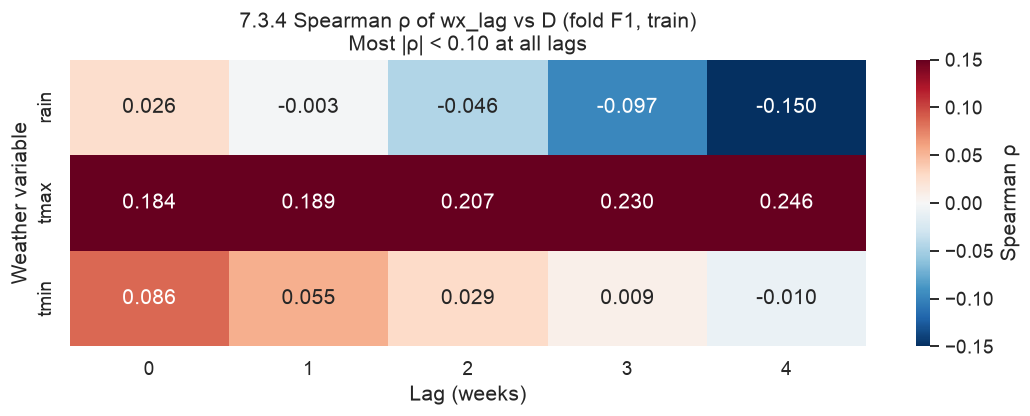

max |ρ| ใน fold F1 (simple, ไม่ partial): 0.2458


In [33]:
# ---- Cell Q: 7.3.4 Lag features visualization ----

# Simple Spearman ρ ระหว่าง wx_lag และ D บน train set ของ fold แรก
fd = get_fold_sql(MAIN_FOLDS[0])
tr = fd["train"]

wx_cols = [f"wx_{v}_lag{k}" for v in ["rain", "tmax", "tmin"] for k in range(5)]
wx_avail = [
    c for c in wx_cols
    if c in tr.columns and tr[c].notna().mean() > 0.5
]

# Spearman ρ กับ D
corrs_simple = {}
for c in wx_avail:
    sub = tr[["D", c]].dropna()
    if len(sub) > 50:
        r, _ = spearmanr(sub["D"], sub[c])
        corrs_simple[c] = r

# Reshape เป็น heatmap
corr_df = pd.DataFrame([
    {"variable": c.split("_")[1], "lag": int(c.split("lag")[1]), "rho": corrs_simple[c]}
    for c in wx_avail if c in corrs_simple
])
pivot = corr_df.pivot(index="variable", columns="lag", values="rho").fillna(0)

fig, ax = plt.subplots(figsize=(10, 4))
sns.heatmap(
    pivot, annot=True, fmt=".3f",
    cmap="RdBu_r", center=0, vmin=-0.15, vmax=0.15, ax=ax,
    cbar_kws={"label": "Spearman ρ"},
)
ax.set_title(
    f"7.3.4 Spearman ρ of wx_lag vs D (fold {MAIN_FOLDS[0]['name']}, train)\nMost |ρ| < 0.10 at all lags"

)
ax.set_xlabel("Lag (weeks)")
ax.set_ylabel("Weather variable")
plt.tight_layout()
plt.show()

max_r = corr_df["rho"].abs().max()
print(f"max |ρ| ใน fold {MAIN_FOLDS[0]['name']} (simple, ไม่ partial): {max_r:.4f}")

MAE ของ Baseline models:


,test_year,Naive (D=0),hist_growth_prev,Seasonal Naive
fold,,,,
F1,2019,0.4225,0.4749,0.3456
F2,2022,0.3511,0.4571,0.3154
F3,2023,0.4112,0.4528,0.3426
F4,2024,0.4036,0.4648,0.3513
F5,2025,0.3754,0.4568,0.3069


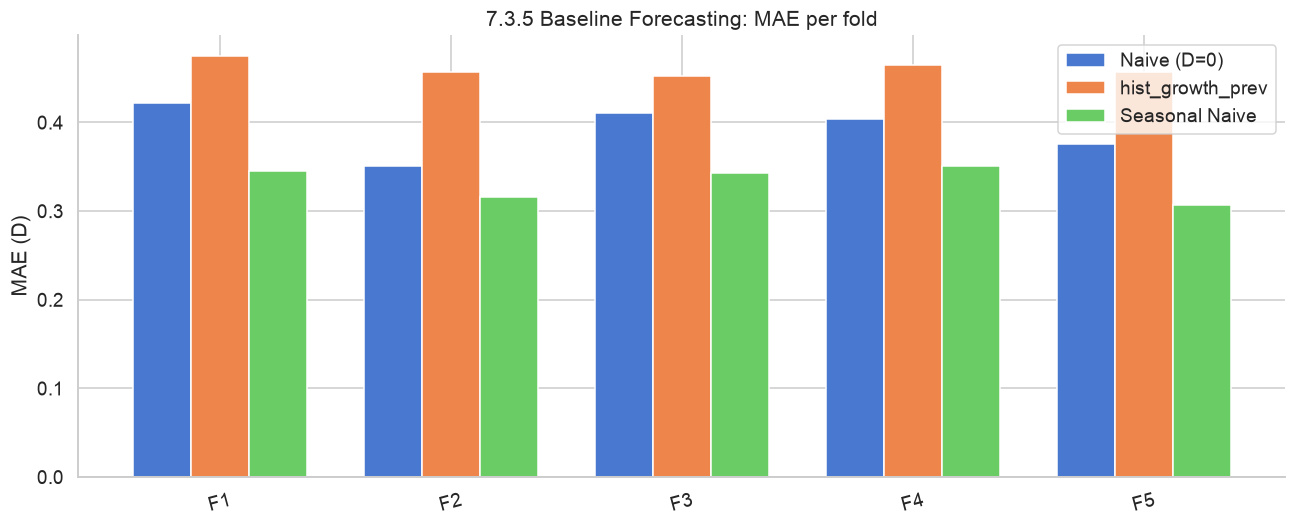

In [34]:
# ---- Cell R: 7.3.5 Baseline forecasting comparison ----

baseline_results = []
for fold in MAIN_FOLDS:
    fd = get_fold_sql(fold)
    tr_f, te = fd["train"], fd["test"]
    y_true = te["D"].values

    # Naive D=0
    mae_naive = float(np.abs(y_true).mean())

    # hist_growth_prev
    if "hist_growth_prev" in te.columns:
        mask_hg = te["hist_growth_prev"].notna()
        mae_hist = float(np.abs(y_true[mask_hg] - te.loc[mask_hg, "hist_growth_prev"].values).mean())
    else:
        mae_hist = float("nan")

    # Seasonal naive: mean D ต่อ Epi week จาก train
    if "Epi week" in tr_f.columns and "Epi week" in te.columns:
        seas_mean = tr_f.groupby("Epi week")["D"].mean()
        seas_pred = te["Epi week"].map(seas_mean).fillna(0).values
        mae_seas = float(np.abs(y_true - seas_pred).mean())
    else:
        mae_seas = float("nan")

    baseline_results.append({
        "fold": fold["name"],
        "test_year": fold["test_year"],
        "Naive (D=0)": round(mae_naive, 4),
        "hist_growth_prev": round(mae_hist, 4),
        "Seasonal Naive": round(mae_seas, 4),
    })

bl_df = pd.DataFrame(baseline_results)
print("MAE ของ Baseline models:")
display(bl_df.set_index("fold"))

# Chart
fig, ax = plt.subplots(figsize=(12, 5))
x = range(len(bl_df))
w = 0.25
metrics = ["Naive (D=0)", "hist_growth_prev", "Seasonal Naive"]
colors_bl = sns.color_palette("muted", len(metrics))
for i, (col, color) in enumerate(zip(metrics, colors_bl)):
    vals = bl_df[col].values
    ax.bar([xi + i * w for xi in x], vals, w, label=col, color=color)
ax.set_xticks([xi + w for xi in x])
ax.set_xticklabels(bl_df["fold"], rotation=15)
ax.set_ylabel("MAE (D)")
ax.set_title("7.3.5 Baseline Forecasting: MAE per fold")
ax.legend()
sns.despine()
plt.tight_layout()
plt.show()

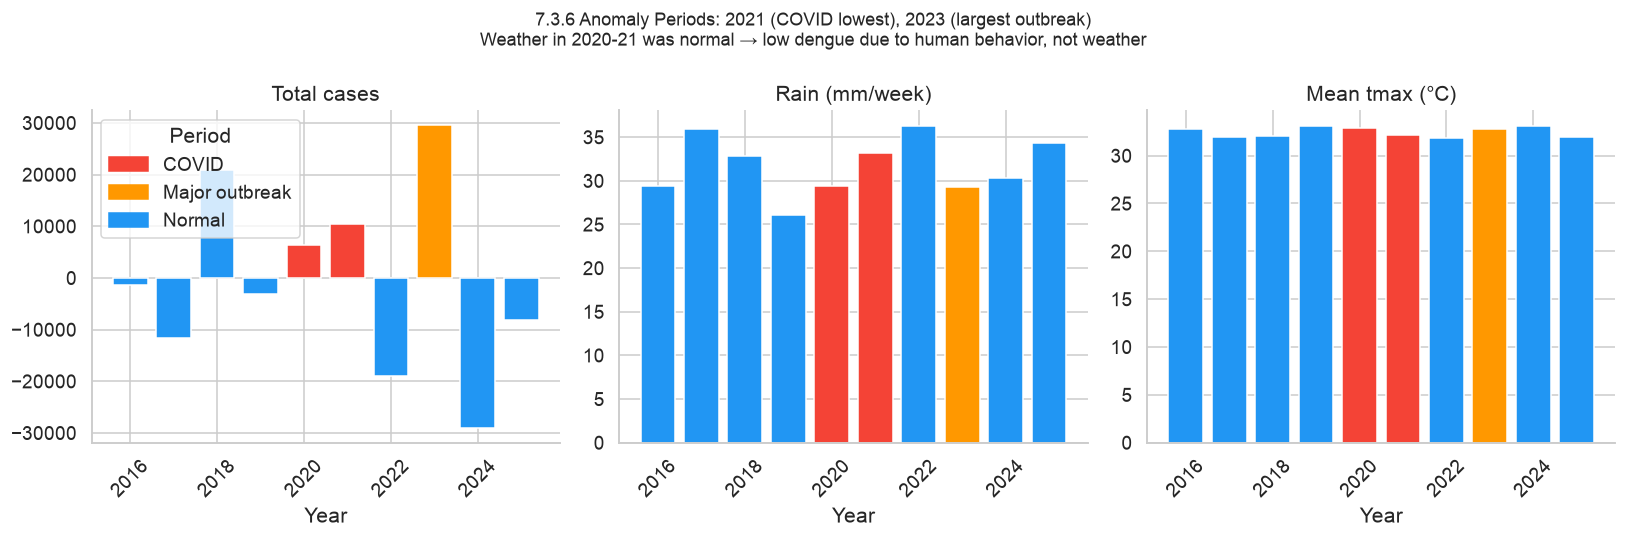

,Year,total_cases,avg_rate,avg_rain,avg_tmax,period_type
0,2016,-1362,1.792633,29.411813,32.772046,Normal
1,2017,-11602,1.463631,35.936588,31.970747,Normal
2,2018,20929,2.453563,32.809651,32.092117,Normal
3,2019,-3083,3.341105,26.063280,33.113926,Normal
4,2020,6313,2.040785,29.414897,32.840598,COVID
5,2021,10469,0.315163,33.132366,32.175176,COVID
6,2022,-18881,1.549162,36.297453,31.886670,Normal
7,2023,29577,4.772160,29.326224,32.756725,Major outbreak
8,2024,-28947,3.171052,30.271760,33.115635,Normal
9,2025,-8132,1.616350,34.374204,31.963807,Normal


In [35]:
# ---- Cell S: 7.3.6 Anomaly periods analysis ----

anomaly_stats = con.execute("""
    SELECT "Year",
           CAST(SUM("Dengue total") AS BIGINT) AS total_cases,
           AVG("Dengue rate per 100,000") AS avg_rate,
           AVG(rain_wk_mm) AS avg_rain,
           AVG(tmax_mean_c) AS avg_tmax,
           CASE
               WHEN "Year" IN (2020, 2021) THEN 'COVID'
               WHEN "Year" = 2023          THEN 'Major outbreak'
               ELSE 'Normal'
           END AS period_type
    FROM mart.trends_weather_latest
    WHERE week_days = 7
    GROUP BY "Year"
    ORDER BY "Year"
""").df()

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
palette = {"COVID": "#F44336", "Major outbreak": "#FF9800", "Normal": "#2196F3"}

for ax, col, title in zip(
    axes,
    ["total_cases", "avg_rain", "avg_tmax"],
    ["Total cases", "Rain (mm/week)", "Mean tmax (°C)"],
):
    colors_a = anomaly_stats["period_type"].map(palette)
    ax.bar(anomaly_stats["Year"], anomaly_stats[col], color=colors_a.values)
    ax.set_title(title)
    ax.set_xlabel("Year")
    ax.tick_params(axis="x", rotation=45)
    sns.despine(ax=ax)

# Legend
from matplotlib.patches import Patch
axes[0].legend(
    handles=[Patch(color=c, label=lbl) for lbl, c in palette.items()],
    title="Period",
)
fig.suptitle(
    "7.3.6 Anomaly Periods: 2021 (COVID lowest), 2023 (largest outbreak)\nWeather in 2020-21 was normal → low dengue due to human behavior, not weather",

    fontsize=12,
)
plt.tight_layout()
plt.show()

display(anomaly_stats)

## สรุปข้อค้นพบสำคัญ

### ผลการทดสอบสมมติฐาน

- **H1 (ฝน) ❌ ไม่ผ่าน** — max partial |ρ| = 0.075 ต่ำกว่าเกณฑ์ 0.10 ทุก lag และทุก fold; ฝนไม่มีสัญญาณเชิงเส้นเพิ่มเติมหลังคุมประวัติโรค

- **H2 (อุณหภูมิ) ❌ ไม่ผ่าน** — tmax มี |ρ| ≈ 0.11 บาง lag เฉพาะ fold F1 (2019) แต่ไม่สม่ำเสมอข้าม fold; เครื่องหมายเดียวกัน ≥4/5 fold ไม่ผ่าน

- **H3 (lag profile) — ตัดสินไม่ได้** — contingent on H1/H2; H1 และ H2 ไม่ผ่านทั้งคู่ จึงไม่มีหลักฐานเพียงพอตัดสิน H3

- **H4 (MAE reduction) ❌ ไม่ผ่าน** — M1 ดีกว่า M0 ใน 1/5 fold (F4=2024, ΔMAE=+5.6%) แต่ F1 แย่ลงมาก (−19.2%); 95% bootstrap CI ไม่ผ่านเกณฑ์ ≥4/5 fold

### ข้อสรุปหลัก

> **อากาศไม่เพิ่มประโยชน์ในการพยากรณ์ไข้เลือดออกในข้อมูลชุดนี้** — ผลลัพธ์นี้อยู่ในช่วงที่ proposal ยอมรับได้

ตัวขับเคลื่อนหลักของการระบาดในชุดข้อมูลนี้คือ:
1. **ประวัติการระบาดระยะสั้น** (hist_logR_prev, hist_growth_prev) — มีอำนาจพยากรณ์สูงสุด
2. **ฤดูกาล** (Fourier features) — peak ช่วงกลางปี สม่ำเสมอข้ามปี
3. **ผลร่วมระดับประเทศ-ปี** (~66% ของความแปรปรวน) — ไม่สามารถ predict ล่วงหน้าด้วยอากาศได้

### ข้อจำกัดของการศึกษา

- **แหล่งอากาศ ERA5 centroid point** — ไม่ใช่ค่าเฉลี่ยเชิงพื้นที่จริงของจังหวัด
- **ข้อมูลเพียง 2-3 รอบการระบาด** (cycle ~3 ปี) — กำลังทางสถิติต่ำในการตรวจจับสัญญาณอ่อน
- **66% ของความแปรปรวนเป็น national-year** — อากาศท้องถิ่นอธิบายความแตกต่างระหว่างจังหวัดในปีเดียวกันได้น้อย
- **COVID-19 (2020-2021)** เป็น structural break — ทำให้ 2 ใน 9 ปีผิดปกติ
- **การไม่พบ H4 ไม่ได้แปลว่าอากาศไม่เกี่ยวข้อง** — อาจต้องการ nonlinear model, spatial lag, หรือ longer lead time